<a href="https://colab.research.google.com/github/francji1/01RAD/blob/main/code/01RAD_Ex05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01RAD - Exercise 05: Multiple Regression: Dummy Variables, Properties of the Estimates, Residuals

Exercise 04 looked at the **multiple linear regression** model (vícerozměrná lineární regrese)

$$\mathbf{Y} = \mathbf{X}\boldsymbol{\beta} + \mathbf{e}, \qquad h(\mathbf{X}) = m+1, \qquad (\ast\ast)$$

with the eyes of linear algebra: the model matrix, the normal equations, the projection matrices $\mathbf{H}$ and $\mathbf{M} = \mathbf{I}_n - \mathbf{H}$, and the numerics of least squares. This exercise follows the lecture slides further (pp. 73–85 and 108–110 of `lectures/01RAD_2024.pdf`):

- Example 3.2: **dummy variables** and **interactions** (birth weight of boys and girls),
- Theorem 3.4 and Theorem 3.5: the distribution of $\widehat{\boldsymbol{\beta}}$ and $s_n^2$,
- Theorem 3.6: the **residual vector** $\widehat{\mathbf{e}}$ of the multiple model; the residuals and studentized residuals of Lecture 4 (Exercise 03) are now written with $h_{ii}$, the diagonal of $\mathbf{H}$,
- the idea of the **overall $F$-test** (celkový $F$-test) and Theorem 3.8.

Section 8 at the end adds what happens with non-normal errors and the **Gauss–Markov theorem** (Theorem 3.7).

The $t$-test and the confidence interval for a single $\beta_j$ follow from Theorem 3.5 (Section 4.3); the $F$ distribution (Theorem 3.9), the ANOVA table and intervals for $\mathsf E(Y|\mathbf{x}_0)$ are left for Exercise 06. R equivalents are mentioned in brackets.

## Learning goals
- Read the coefficients of a model with a **dummy variable** (indikátorová proměnná) and with an **interaction** (interakce): write the regression line of each group, interpret each coefficient with units, and know what changes when the reference level or the centering of $x$ changes.
- State Theorems 3.4 and 3.5 and check every point by a simulation with a **fixed** model matrix: unbiasedness, $\mathsf{Cov}\,\widehat{\boldsymbol{\beta}} = \sigma^2(\mathbf{X}^T\mathbf{X})^{-1}$, $\mathsf E\,s_n^2 = \sigma^2$, the $\chi^2$ and $t$ distributions, the independence of $\widehat{\boldsymbol{\beta}}$ and $s_n^2$; derive the $t$-test and the confidence interval for $\beta_j$ and check the coverage.
- Compute the standard errors $s_n\sqrt{v_j}$ and the correlation of the estimates from $(\mathbf{X}^T\mathbf{X})^{-1}$, and explain why correlated regressors give correlated estimates.
- Verify Theorem 3.6 ($\mathsf{Cov}\,\widehat{\mathbf{e}} = \sigma^2(\mathbf{I}_n - \mathbf{H})$), compute the internally studentized residuals $\widehat{r}_i = \widehat{e}_i / (s_n\sqrt{1-h_{ii}})$ and read the residual plots of a multiple model; know why residuals are plotted against $\widehat{y}$ and not against $y$.
- Explain why many individual $t$-tests are no substitute for one overall test, and what $\mathsf E(\mathrm{SSR}/m)$ says about the statistic $F$.

Theorem and remark numbers refer to the lecture slides `lectures/01RAD_2024.pdf` (Example 3.2 on p. 73, Theorem 3.4 on p. 74, Theorem 3.5 on p. 76, Theorem 3.6 on p. 78, Gauss–Markov on pp. 80–81, overall $F$-test and Theorem 3.8 on pp. 82–85, residuals of the multiple model on pp. 108–110, which the lecture will reach in the chapter on residuals).

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.linalg as sla
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from patsy import dmatrices

sns.set_theme(style='whitegrid', palette='deep')
pd.set_option('display.precision', 4)
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(2026)

In [2]:
url_mpg = 'https://raw.githubusercontent.com/francji1/01RAD/main/data/mpg.csv'
try:
    mpg_raw = pd.read_csv(url_mpg)
except Exception:
    mpg_raw = sns.load_dataset('mpg')          # the same data set ships with seaborn
cars = mpg_raw.dropna().reset_index(drop=True)
print(f'{cars.shape[0]} cars')


# helper functions from Exercise 04
def ols_qr(X, y):
    Q, R = np.linalg.qr(X)                                    # Householder QR (LAPACK)
    return sla.solve_triangular(R, Q.T @ y)


def ols_svd(X, y, rtol=1e-12):
    P, s, Qt = np.linalg.svd(X, full_matrices=False)          # X = P diag(s) Q^T
    s_inv = np.where(s > rtol * s[0], 1 / s, 0.0)             # pseudoinverse: drop zero singular values
    return Qt.T @ (s_inv * (P.T @ y))


def residual_maker(Z):
    """Residuals of the projection onto the columns of Z, as a function."""
    Q_z, _ = np.linalg.qr(Z)
    return lambda v: v - Q_z @ (Q_z.T @ v)

392 cars


## 2. Solution of the individual work from Exercise 04
The task: `sales` (thousands of units) against the advertising budgets for `TV`, `radio` and `newspaper` (thousands of dollars) in 200 markets, now with all three media in one model, in seven steps. We go through the steps one by one; the numbers quoted in the text are those of the executed cells.

In [3]:
url_adv = 'https://raw.githubusercontent.com/francji1/01RAD/main/data/Advert.csv'
advert = pd.read_csv(url_adv, index_col=0)

# step 1: the model matrix by hand and by patsy
ya_adv = advert['sales'].to_numpy(dtype=float)
Xa_adv = np.column_stack([np.ones(len(advert)), advert[['TV', 'radio', 'newspaper']].to_numpy(dtype=float)])
yd, Xd = dmatrices('sales ~ TV + radio + newspaper', data=advert, return_type='dataframe')
print('shape', Xa_adv.shape, ' columns from patsy:', list(Xd.columns))
print('max |difference| =', np.abs(Xa_adv - Xd.to_numpy()).max())

shape (200, 4)  columns from patsy: ['Intercept', 'TV', 'radio', 'newspaper']
max |difference| = 0.0


**Step 1.** $n = 200$, $m + 1 = 4$ columns: the column of ones and the three budgets. The model matrix of a formula with numerical variables only is just the data with a column of ones in front; `dmatrices` starts to matter with factors, interactions and transformations (Section 3).

**Step 2.** QR, SVD, `statsmodels`, and the slopes of the three simple regressions from Exercise 03.

In [4]:
adv_full = smf.ols('sales ~ TV + radio + newspaper', data=advert).fit()   # R: lm(sales ~ TV + radio + newspaper)
b_qr = ols_qr(Xa_adv, ya_adv)
b_svd = ols_svd(Xa_adv, ya_adv)
simple = [np.nan] + [smf.ols(f'sales ~ {v}', data=advert).fit().params[v] for v in ['TV', 'radio', 'newspaper']]
tab = pd.DataFrame({'QR': b_qr, 'SVD': b_svd, 'statsmodels': adv_full.params.values, 'simple regression': simple},
                   index=adv_full.params.index)
tab['relative change'] = (tab['statsmodels'] - tab['simple regression']) / tab['simple regression']
tab

,QR,SVD,statsmodels,simple regression,relative change
Intercept,2.9389,2.9389,2.9389,NaN,NaN
TV,0.0458,0.0458,0.0458,0.0475,-0.0373
radio,0.1885,0.1885,0.1885,0.2025,-0.0690
newspaper,-0.0010,-0.0010,-0.0010,0.0547,-1.0190


QR, SVD and `statsmodels` agree to all printed digits, as they should for a well-conditioned $\mathbf{X}$ (step 6). Compared with the simple regressions, `TV` hardly changes ($0.0475 \to 0.0458$, about $-4$ %) and `radio` a little ($0.203 \to 0.189$, about $-7$ %), but `newspaper` drops from $0.055$ to $-0.001$, i.e. by about 102 %, practically to zero. Note the interpretation of a coefficient in the multiple model: $\widehat{\beta}_{\text{TV}} = 0.0458$ means that **for the same radio and newspaper budgets**, an extra 1000 dollars on TV goes with about 46 more units sold on average. The simple regression slope compares markets that differ in TV *and* possibly in everything else.

**Step 3.** Orthogonality, trace and $R^2$.

In [5]:
fit_adv = Xa_adv @ b_qr
res_adv = ya_adv - fit_adv
Q_adv, R_adv = np.linalg.qr(Xa_adv)
h_adv = np.sum(Q_adv ** 2, axis=1)                  # diag(Q Q^T) = diag(H), without the 200 x 200 matrix
print('X^T e_hat / |X^T y| :', np.abs(Xa_adv.T @ res_adv) / np.abs(Xa_adv.T @ ya_adv))
print(f'tr(H) = sum h_ii = {h_adv.sum():.6f},  m + 1 = {Xa_adv.shape[1]}')
print(f'R^2 = {adv_full.rsquared:.6f},  corr(y, y_hat)^2 = {np.corrcoef(ya_adv, fit_adv)[0, 1] ** 2:.6f}')

X^T e_hat / |X^T y| : [0. 0. 0. 0.]
tr(H) = sum h_ii = 4.000000,  m + 1 = 4
R^2 = 0.897211,  corr(y, y_hat)^2 = 0.897211


All three checks hold to rounding (the relative size of $\mathbf{X}^T\widehat{\mathbf{e}}$ prints as $0$ at four decimals; it is of the order $10^{-16}$, machine precision).
- $\mathbf{X}^T\widehat{\mathbf{e}} = \mathbf{0}$ are the normal equations: the residuals are orthogonal to every column, in particular $\sum_i \widehat{e}_i = 0$ (column of ones) and $\sum_i \widehat{e}_i x_{ij} = 0$ for each medium.
- $\mathrm{tr}(\mathbf{H}) = m + 1 = 4$ is the number of estimated coefficients, the dimension of $\mathcal{M}(\mathbf{X})$.
- A useful trick for large $n$: with $\mathbf{X} = \mathbf{Q}\mathbf{R}$ we have $\mathbf{H} = \mathbf{Q}\mathbf{Q}^T$, so $h_{ii}$ is the squared norm of the $i$-th row of $\mathbf{Q}$ and the $n \times n$ matrix $\mathbf{H}$ is never needed.
- $R^2 = 0.897$: the three budgets together explain about 90 % of the variability of sales; in Exercise 03 TV alone explained about 61 %.

**Step 4.** Frisch–Waugh–Lovell for `newspaper`.

,TV,radio,newspaper,sales
TV,1.000,0.055,0.057,0.782
radio,0.055,1.000,0.354,0.576
newspaper,0.057,0.354,1.000,0.228
sales,0.782,0.576,0.228,1.000


{'Intercept': 17.1466, 'TV': 0.0095, 'radio': 0.5164}  R^2 = 0.127
FWL slope = -0.001037,  multiple regression = -0.001037
p-value of newspaper in the multiple regression (summary): 0.86


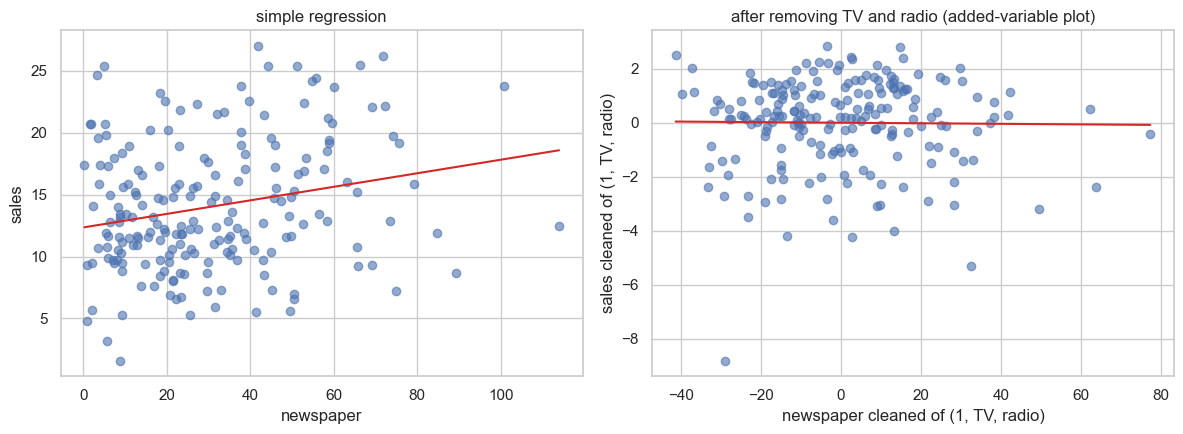

In [6]:
display(advert[['TV', 'radio', 'newspaper', 'sales']].corr().round(3))
aux = smf.ols('newspaper ~ TV + radio', data=advert).fit()
print(aux.params.round(4).to_dict(), f' R^2 = {aux.rsquared:.3f}')

M_tr = residual_maker(Xa_adv[:, :3])                # intercept, TV, radio
news_t, sales_t = M_tr(Xa_adv[:, 3]), M_tr(ya_adv)
print(f'FWL slope = {(news_t @ sales_t) / (news_t @ news_t):.6f},  multiple regression = {adv_full.params["newspaper"]:.6f}')
print(f'p-value of newspaper in the multiple regression (summary): {adv_full.pvalues["newspaper"]:.2f}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(advert['newspaper'], ya_adv, alpha=0.6)
axes[0].plot(np.sort(advert['newspaper']), np.polyval(np.polyfit(advert['newspaper'], ya_adv, 1), np.sort(advert['newspaper'])), color='tab:red')
axes[0].set_xlabel('newspaper'); axes[0].set_ylabel('sales'); axes[0].set_title('simple regression')
axes[1].scatter(news_t, sales_t, alpha=0.6)
axes[1].plot(np.sort(news_t), adv_full.params['newspaper'] * np.sort(news_t), color='tab:red')
axes[1].set_xlabel('newspaper cleaned of (1, TV, radio)'); axes[1].set_ylabel('sales cleaned of (1, TV, radio)')
axes[1].set_title('after removing TV and radio (added-variable plot)')
plt.tight_layout()
plt.show()

- `newspaper` is correlated with `radio` ($r \approx 0.35$) and hardly with `TV` ($r \approx 0.06$). In the auxiliary regression the coefficient of radio is about $0.52$: markets with a large radio budget tend to have a large newspaper budget as well.
- Higher radio budgets go with higher sales, at fixed TV and newspaper budgets. In the simple regression, newspaper "borrows" the effect of radio and gets a positive slope; this is the classical **omitted variable** situation.
- After removing TV and radio from both variables, the cloud in the right panel is flat: the part of the newspaper budget that is not explained by the radio and TV budgets has no linear relation to sales. The FWL slope equals the multiple regression coefficient exactly.
- The auxiliary $R^2 = 0.13$ is small, so most of the newspaper variability survives the cleaning; the coefficient is estimated from plenty of information and is genuinely close to zero, it is not a collinearity artefact.
- Careful with the business conclusion: the data say that, *given* the TV and radio budgets, the newspaper budget does not predict sales. They do not prove that newspaper advertising has no effect, because the budgets were not assigned at random (Exercise 03, correlation is not causation).
- Whether $-0.001$ differs significantly from zero is a $t$-test in the multiple model; `summary()` gives $p \approx 0.86$. Section 4.3 shows the distribution behind the $t$ column (Theorem 3.5) and the test built on it.

**Step 5.** The largest leverages.

In [7]:
top_adv = np.argsort(h_adv)[::-1][:5]
display(advert.iloc[top_adv].assign(h_ii=h_adv[top_adv]))
print(f'mean leverage (m+1)/n = {h_adv.mean():.3f};  rule of thumb 2(m+1)/n = {2 * h_adv.mean():.3f}, 3(m+1)/n = {3 * h_adv.mean():.3f}')
print(f'markets with h_ii > 3(m+1)/n: {(h_adv > 3 * h_adv.mean()).sum()}')
print('quantiles of the budgets:')
display(advert[['TV', 'radio', 'newspaper']].quantile([0, 0.25, 0.5, 0.75, 1]).T)

,TV,radio,newspaper,sales,h_ii
17,67.8,36.6,114.0,12.5,0.0863
102,296.4,36.3,100.9,23.8,0.0702
166,234.5,3.4,84.8,11.9,0.0692
76,16.9,43.7,89.4,8.7,0.0570
6,8.7,48.9,75.0,7.2,0.0475


mean leverage (m+1)/n = 0.020;  rule of thumb 2(m+1)/n = 0.040, 3(m+1)/n = 0.060
markets with h_ii > 3(m+1)/n: 3
quantiles of the budgets:


,0.00,0.25,0.50,0.75,1.00
TV,0.7,74.375,149.75,218.825,296.4
radio,0.0,9.975,22.90,36.525,49.6
newspaper,0.3,12.750,25.75,45.100,114.0


All five markets have an **unusually large newspaper budget** (75 to 114, while the median is about 26 and the upper quartile 45); market 17 has the maximum 114. The others combine a large newspaper budget with an extreme TV budget (296.4 is the maximum, 8.7 and 16.9 are among the smallest) or with almost no radio (3.4).

Leverage $h_{ii}$ depends only on $\mathbf{X}$: it measures how far the market lies from the center of the **regressors**, not how unusual its sales are. Three markets exceed the threshold $3(m+1)/n = 0.06$ of the slides ($h_{ii} \approx 0.086$, $0.070$ and $0.069$; p. 110, in the chapter on residuals that the lecture will come to, Section 5 takes it in advance). Such points pull the fitted plane towards themselves, so they deserve a look in the diagnostics (Exercise 07: influence measures combine $h_{ii}$ with the residual). Here they are ordinary markets with an unusual budget mix, not errors in the data.

**Step 6.** Condition number.

In [8]:
Z_adv = Xa_adv.copy()
Z_adv[:, 1:] = (Z_adv[:, 1:] - Z_adv[:, 1:].mean(axis=0)) / Z_adv[:, 1:].std(axis=0)
print(f'raw: kappa(X) = {np.linalg.cond(Xa_adv):.1f},  kappa(X^T X) = {np.linalg.cond(Xa_adv.T @ Xa_adv):.3e}')
print(f'standardized: kappa(X) = {np.linalg.cond(Z_adv):.2f}')

raw: kappa(X) = 454.4,  kappa(X^T X) = 2.065e+05
standardized: kappa(X) = 1.46


$\kappa(\mathbf{X}) \approx 450$ for the raw budgets and $\approx 1.5$ after standardization. Even the normal equations, with $\kappa(\mathbf{X}^T\mathbf{X}) = \kappa(\mathbf{X})^2 \approx 2\cdot 10^5$, lose at most about 5 of the 16 digits of double precision: no numerical problem. The raw value is large only because the columns have different scales (the column of ones versus budgets in the hundreds), which standardization removes.

After standardization the regressor columns are orthogonal to the column of ones, and $\kappa$ is the square root of the ratio of the largest and smallest eigenvalue of the correlation matrix of the budgets. A value close to 1 says that the budgets are only weakly correlated: no collinearity (the largest correlation is radio–newspaper, 0.35).

**Step 7.** Adding `total = TV + radio + newspaper`.

In [9]:
X_tot = np.column_stack([Xa_adv, Xa_adv[:, 1:].sum(axis=1)])
print('rank:', np.linalg.matrix_rank(X_tot), ' of', X_tot.shape[1], 'columns')
print('singular values:', np.array2string(np.linalg.svd(X_tot, compute_uv=False), precision=3, floatmode='maxprec'))
print('|r_55| of the QR decomposition:', f'{abs(np.linalg.qr(X_tot)[1][-1, -1]):.1e}')

fit_tot = sm.OLS(ya_adv, X_tot).fit()
b_qr_tot = ols_qr(X_tot, ya_adv)
names_tot = ['Intercept', 'TV', 'radio', 'newspaper', 'total']
display(pd.DataFrame({'statsmodels (pinv)': fit_tot.params, 'own QR': b_qr_tot}, index=names_tot))
print('statsmodels: max |fitted - fitted of the full model| =', np.abs(fit_tot.fittedvalues - adv_full.fittedvalues.values).max(),
      ', df_resid =', fit_tot.df_resid)
print('own QR     : max |fitted - fitted of the full model| =', np.abs(X_tot @ b_qr_tot - adv_full.fittedvalues.values).max())
print('statsmodels: medium + total =', (fit_tot.params[1:4] + fit_tot.params[4]).round(4),
      ' full model:', adv_full.params.values[1:].round(4))

rank: 4  of 5 columns
singular values: [3967.238  485.935  197.426    5.404    0.   ]
|r_55| of the QR decomposition: 9.0e-13


,statsmodels (pinv),own QR
Intercept,2.9389,2.8502e+00
TV,-0.0125,-1.4175e+12
radio,0.1302,-1.4175e+12
newspaper,-0.0594,-1.4175e+12
total,0.0583,1.4175e+12


statsmodels: max |fitted - fitted of the full model| = 2.1316282072803006e-14 , df_resid = 196.0
own QR     : max |fitted - fitted of the full model| = 0.17141243614343438
statsmodels: medium + total = [ 0.0458  0.1885 -0.001 ]  full model: [ 0.0458  0.1885 -0.001 ]


The rank is 4 with 5 columns, the smallest singular value is zero up to rounding (Theorem 3.3: dependent columns, singular $\mathbf{X}^T\mathbf{X}$, infinitely many solutions of the normal equations).
- `statsmodels` returns the **minimum-norm solution**: each medium gets its "own" part plus a common part on `total`. The individual coefficients are not identified, only the combinations `medium + total`, which equal the coefficients of the full model. The fitted values are the same (one projection, many parametrizations) and the residual degrees of freedom are $196 = n - \text{rank}$.
- Our QR solution without pivoting divides by $r_{55}$, which is a rounding error (of the order $10^{-12}$ in this run) instead of zero. It returns huge coefficients (here of the order $\pm 10^{12}$), and even the fitted values are visibly off (here by about $0.17$), because the huge coefficients cancel only approximately. The exact numbers depend on the linear algebra library and may differ in Colab; the effect does not. This is why R's `lm` uses QR **with column pivoting** and reports `NA` for the column whose $r_{jj}$ is numerically zero, and why `statsmodels` uses the pseudoinverse with a tolerance for small singular values.
- In practice: when software silently returns huge coefficients, a warning about a small eigenvalue, or `NA`, look for an exact linear relation among the regressors (sums, shares adding to 100 %, all dummies of a factor together with the intercept).

**Summary of the individual work.** In the multiple model, TV and radio matter and newspaper does not, given the other two; the positive simple slope of newspaper came from its correlation with radio (FWL). The fit is good ($R^2 \approx 0.90$), the regressors are well conditioned, and the markets with the largest leverage are those with an unusual budget mix.

## 3. Dummy variables and interactions
### 3.1 Example 3.2: birth weight of boys and girls
The data of Example 2.4 (Exercise 03): birth weight (g) and gestational age (weeks) of 12 boys and 12 girls. In Exercise 03 we ignored the sex. Define the **dummy variable** (indikátorová, umělá proměnná)

$$x_2 = \begin{cases} 0, & \text{boy}, \\ 1, & \text{girl}, \end{cases}$$

and consider the model $Y = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + e$ with $x_1$ = age. It describes **two parallel lines**,

$$\text{boys: } \beta_0 + \beta_1 x_1, \qquad \text{girls: } (\beta_0 + \beta_2) + \beta_1 x_1 .$$

For different slopes we add the **interaction** $x_1 x_2$: $Y = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \beta_3 x_1 x_2 + e$, so that girls have the line $(\beta_0 + \beta_2) + (\beta_1 + \beta_3)x_1$. In the formula language `Age * Sex` means `Age + Sex + Age:Sex` (R: `lm(Weight ~ Age * Sex)` or `lm(Weight ~ Age + Sex + Age:Sex)`).

In [10]:
birth = pd.DataFrame({
    'Age': [40, 38, 40, 35, 36, 37, 41, 40, 37, 38, 40, 38,
            40, 36, 40, 38, 42, 39, 40, 37, 36, 38, 39, 40],
    'Weight': [2968, 2795, 3163, 2925, 2625, 2847, 3292, 3473, 2628, 3176, 3421, 2975,
               3317, 2729, 2935, 2754, 3210, 2817, 3126, 2539, 2412, 2991, 2875, 3231],
    'Sex': ['boy'] * 12 + ['girl'] * 12})

b_one = smf.ols('Weight ~ Age', data=birth).fit()              # Exercise 03
b_par = smf.ols('Weight ~ Age + Sex', data=birth).fit()        # R: lm(Weight ~ Age + Sex)
b_int = smf.ols('Weight ~ Age * Sex', data=birth).fit()        # R: lm(Weight ~ Age + Sex + Age:Sex)

print(dmatrices('Weight ~ Age * Sex', data=birth, return_type='dataframe')[1].iloc[[0, 1, 12, 13]])
pd.DataFrame({'Age only': b_one.params, 'parallel lines': b_par.params, 'interaction': b_int.params,
              'slide (interaction)': pd.Series({'Intercept': -1268.67, 'Age': 111.98, 'Sex[T.girl]': -872.99,
                                                'Age:Sex[T.girl]': 18.42})}).loc[
    ['Intercept', 'Age', 'Sex[T.girl]', 'Age:Sex[T.girl]']]

    Intercept  Sex[T.girl]   Age  Age:Sex[T.girl]
0         1.0          0.0  40.0              0.0
1         1.0          0.0  38.0              0.0
12        1.0          1.0  40.0             40.0
13        1.0          1.0  36.0             36.0


,Age only,parallel lines,interaction,slide (interaction)
Intercept,-1484.9846,-1610.2825,-1268.6724,-1268.67
Age,115.5283,120.8943,111.9828,111.98
Sex[T.girl],NaN,-163.0393,-872.9943,-872.99
Age:Sex[T.girl],NaN,NaN,18.4172,18.42


In [11]:
print(b_int.summary().tables[1])
print(f's_n = {np.sqrt(b_int.scale):.1f} on {b_int.df_resid:.0f} degrees of freedom, R^2 = {b_int.rsquared:.4f}')

                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept       -1268.6724   1114.638     -1.138      0.268   -3593.767    1056.423
Sex[T.girl]      -872.9943   1611.331     -0.542      0.594   -4234.172    2488.183
Age               111.9828     29.046      3.855      0.001      51.395     172.571
Age:Sex[T.girl]    18.4172     41.756      0.441      0.664     -68.684     105.518
s_n = 180.6 on 20 degrees of freedom, R^2 = 0.6435


The interaction model reproduces the slide: $\widehat{\beta} = (-1268.67,\ 111.98,\ -872.99,\ 18.42)$, `Residual standard error: 180.6 on 20 degrees of freedom`, $R^2 = 0.6435$. (The `t` and `P>|t|` columns rest on Theorem 3.5, Section 4.3; the `F-statistic` line is the topic of Exercise 06.)

**Parallel lines.** $\widehat{\beta}_2 = -163$ g: a girl of the **same gestational age** as a boy weighs on average 163 g less. The common slope $\approx 121$ g per week is slightly larger than in Exercise 03 ($115.5$), where the sex was ignored. The girls in the sample are slightly older on average, so part of the weekly increase was hidden by the lower weight of girls; the same omitted-variable mechanism as with newspaper and radio in Section 2, here much weaker.

**Interaction.** The two lines are

$$\text{boys: } -1268.7 + 112.0\cdot\text{Age}, \qquad \text{girls: } (-1268.7 - 873.0) + (112.0 + 18.4)\cdot\text{Age} = -2141.7 + 130.4\cdot\text{Age}.$$

- $\widehat{\beta}_3 = 18.4$ g per week is the **difference of the slopes**; its $t$ value $0.44$ shows that it is small compared with its standard error $41.8$, the data give no reason for different slopes.
- $\widehat{\beta}_2 = -873$ g is the difference between girls and boys **at age 0 weeks**, a huge extrapolation (the data cover 35–42 weeks), hence the enormous standard error $1611$. With an interaction in the model, the dummy coefficient is a difference at one particular value of $x_1$, namely $x_1 = 0$.

Centering the age makes the dummy coefficient meaningful: with $x_1 - 38$ it is the difference at 38 weeks.

,coef,std err
Intercept,2986.6724,53.0299
Sex[T.girl],-173.1391,77.6969
I(Age - 38),111.9828,29.0457
I(Age - 38):Sex[T.girl],18.4172,41.7558


same fitted values as the uncentered model: True


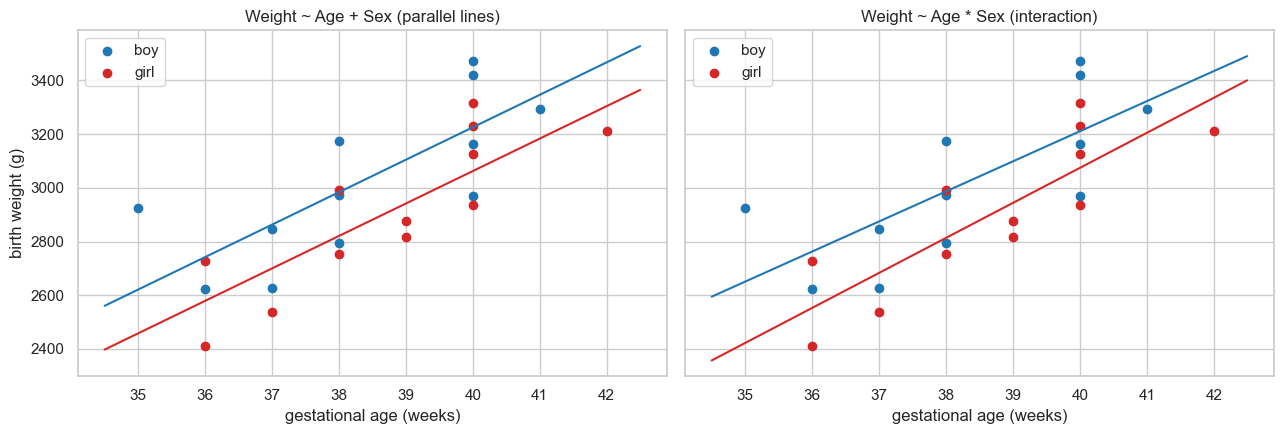

In [12]:
b_int38 = smf.ols('Weight ~ I(Age - 38) * Sex', data=birth).fit()     # R: lm(Weight ~ I(Age - 38) * Sex)
display(pd.DataFrame({'coef': b_int38.params, 'std err': b_int38.bse}))
print('same fitted values as the uncentered model:', np.allclose(b_int38.fittedvalues, b_int.fittedvalues))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
grid = np.linspace(34.5, 42.5, 50)
for ax, fit, title in [(axes[0], b_par, 'Weight ~ Age + Sex (parallel lines)'),
                       (axes[1], b_int, 'Weight ~ Age * Sex (interaction)')]:
    for sex, col in [('boy', 'tab:blue'), ('girl', 'tab:red')]:
        d = birth[birth['Sex'] == sex]
        ax.scatter(d['Age'], d['Weight'], color=col, label=sex)
        ax.plot(grid, fit.predict(pd.DataFrame({'Age': grid, 'Sex': sex})), color=col)
    ax.set_xlabel('gestational age (weeks)'); ax.set_title(title); ax.legend()
axes[0].set_ylabel('birth weight (g)')
plt.tight_layout()
plt.show()

Centering changes $\widehat{\beta}_0$ and $\widehat{\beta}_2$ but not the slopes, the interaction, or the fitted values: it is the reparametrization $\widetilde{\mathbf{X}} = \mathbf{X}\mathbf{A}$ of Exercise 04, the column space is the same. At 38 weeks girls are about $173$ g lighter, with standard error $78$ instead of $1611$.

**Exercise on the board.**
1. Write the rows of the model matrix of `Weight ~ Age * Sex` for a boy aged 40 weeks and for a girl aged 40 weeks. Use the order of the slides, $(1, x_1, x_2, x_1x_2)$; patsy prints the same columns in a different order.
2. Sort the rows so that the 12 boys come first. Show that the column space of the interaction model is the same as the column space of the block-diagonal matrix $\begin{pmatrix}\mathbf{X}_b & \mathbf{0}\\ \mathbf{0} & \mathbf{X}_g\end{pmatrix}$ with $\mathbf{X}_b = (\mathbf{1}, \mathbf{age}_b)$, $\mathbf{X}_g = (\mathbf{1}, \mathbf{age}_g)$.
3. Conclude what this means for the two fitted lines compared with two separate simple regressions, one for boys and one for girls. Is anything different between the two approaches?

<!--
Solution.
1. Columns (1, Age, girl, Age*girl), the order of the slides: boy aged 40: (1, 40, 0, 0); girl aged 40: (1, 40, 1, 40).
   (patsy prints them as Intercept, Sex[T.girl], Age, Age:Sex[T.girl].)
2. With boys first, X = [[1_b, a_b, 0, 0], [1_g, a_g, 1_g, a_g]]. Columns 3 and 4 are (0; 1_g) and (0; a_g), the girls' block.
   Columns 1 - 3 = (1_b; 0) and 2 - 4 = (a_b; 0) are the boys' block. So X = D A with D = blockdiag(X_b, X_g) and a regular
   4x4 matrix A (the columns of X are combinations of the columns of D and vice versa): the same column space, the same H.
3. Same H, same fitted values. In the block-diagonal model the normal equations split into two independent systems,
   one for the boys and one for the girls, i.e. exactly the two separate simple regressions. Hence the interaction model
   gives the same two lines as the separate regressions: boys -1268.7 + 112.0 Age, girls -2141.7 + 130.4 Age.
-->

### 3.2 A factor with three levels: `mpg ~ weight * origin`
The factor `origin` has three levels; with the intercept it gives two dummies, `origin[T.japan]` and `origin[T.usa]`, and the first level `europe` is the **reference level** (referenční úroveň). The interaction `weight:origin` gives each origin its own slope.

,coef,std err,t
Intercept,44.2732,2.62226,16.8836
origin[T.japan],9.98693,4.27144,2.33807
origin[T.usa],-1.12475,2.87804,-0.390803
weight,-0.00685041,0.00105653,-6.48388
weight:origin[T.japan],-0.00386867,0.00183688,-2.10611
weight:origin[T.usa],-3.57515e-06,0.00111061,-0.00321909


,intercept from the model,slope from the model,"slope, separate regression"
europe,44.2732,-0.00685041,-0.00685041
japan,54.2602,-0.0107191,-0.0107191
usa,43.1485,-0.00685399,-0.00685399


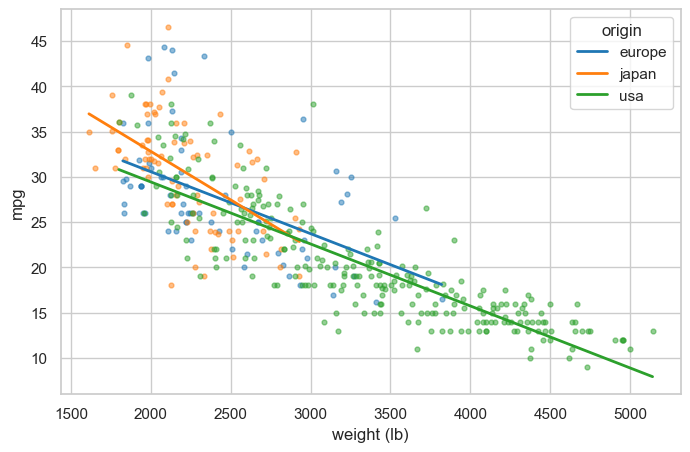

In [13]:
m_orig = smf.ols('mpg ~ weight * origin', data=cars).fit()       # R: lm(mpg ~ weight * origin, data = cars)
coef = m_orig.params
lines = pd.DataFrame({
    'intercept from the model': [coef['Intercept'], coef['Intercept'] + coef['origin[T.japan]'], coef['Intercept'] + coef['origin[T.usa]']],
    'slope from the model': [coef['weight'], coef['weight'] + coef['weight:origin[T.japan]'], coef['weight'] + coef['weight:origin[T.usa]']],
    'slope, separate regression': [smf.ols('mpg ~ weight', data=cars[cars['origin'] == o]).fit().params['weight']
                                   for o in ['europe', 'japan', 'usa']]},
    index=['europe', 'japan', 'usa'])
with pd.option_context('display.float_format', '{:.6g}'.format):
    display(pd.DataFrame({'coef': coef, 'std err': m_orig.bse, 't': m_orig.tvalues}))
    display(lines)

plt.figure(figsize=(8, 5))
wgrid = np.linspace(cars['weight'].min(), cars['weight'].max(), 50)
for o, col in zip(['europe', 'japan', 'usa'], ['tab:blue', 'tab:orange', 'tab:green']):
    d = cars[cars['origin'] == o]
    plt.scatter(d['weight'], d['mpg'], s=12, alpha=0.5, color=col)
    w = np.linspace(d['weight'].min(), d['weight'].max(), 50)
    plt.plot(w, lines.loc[o, 'intercept from the model'] + lines.loc[o, 'slope from the model'] * w, color=col, lw=2, label=o)
plt.xlabel('weight (lb)'); plt.ylabel('mpg'); plt.legend(title='origin')
plt.show()

- The coefficients without `origin` in the name belong to the reference level: Europe has the line $44.27 - 0.00685\cdot\text{weight}$.
- `origin[T.japan]` $= 9.99$ and `weight:origin[T.japan]` $= -0.00387$ are **differences** from Europe: Japanese cars have the line $54.26 - 0.01072\cdot\text{weight}$, i.e. a steeper decrease of mpg with weight.
- `weight:origin[T.usa]` is zero to five decimals: in these data the American and European lines have practically the same slope, and the intercepts differ by about 1 mpg. Its standard error $0.0011$ is 300 times larger than the estimate, so the exact agreement is a coincidence of this sample, not a proof of equal slopes.
- The slopes agree exactly with three separate regressions, as in the board exercise.
- The Japanese cars cover only light weights (up to about 2900 lb), the American ones mostly heavy cars. Comparing the origins "at the same weight" is reliable only where the weight ranges overlap.

The reference level is a choice. Changing it changes the coefficients (they become differences from another group) but not the model: the fitted values are the same.

In [14]:
m_usa = smf.ols('mpg ~ weight * C(origin, Treatment("usa"))', data=cars).fit()   # R: relevel(origin, ref = "usa")
with pd.option_context('display.float_format', '{:.6g}'.format):
    display(m_usa.params.to_frame('coef, reference usa'))
print('max |fitted values (reference europe) - fitted values (reference usa)| =',
      np.abs(m_orig.fittedvalues - m_usa.fittedvalues).max())

,"coef, reference usa"
Intercept,43.1485
"C(origin, Treatment(""usa""))[T.europe]",1.12475
"C(origin, Treatment(""usa""))[T.japan]",11.1117
weight,-0.00685399
"weight:C(origin, Treatment(""usa""))[T.europe]",3.57515e-06
"weight:C(origin, Treatment(""usa""))[T.japan]",-0.00386509


max |fitted values (reference europe) - fitted values (reference usa)| = 5.399147795515091e-11


### 3.3 A promise from Exercise 03: comparing two slopes
In the individual work of Exercise 02 (solution in Exercise 03, Section 2) we compared the slope of fuel consumption on power for European cars with the slope for all cars by looking at overlapping confidence intervals, and noted that this is only an informal check. The proper way is one model with an interaction: `europe` is a dummy (1 for European cars), and the interaction coefficient is the difference of the slopes, estimated with its own standard error.

In [15]:
cars['l_per_100km'] = 235.215 / cars['mpg']
cars['kw'] = 0.7457 * cars['horsepower']
cars['europe'] = (cars['origin'] == 'europe').astype(int)
fuel_eu = smf.ols('l_per_100km ~ kw * europe', data=cars).fit()      # R: lm(l_per_100km ~ kw * europe)
pd.DataFrame({'coef': fuel_eu.params, 'std err': fuel_eu.bse, 't': fuel_eu.tvalues, 'P>|t|': fuel_eu.pvalues})

,coef,std err,t,P>|t|
Intercept,2.2228,0.3333,6.6683,8.9226e-11
kw,0.1164,0.0038,30.2953,2.7302e-104
europe,0.5938,1.0768,0.5515,5.8163e-01
kw:europe,-0.0136,0.0170,-0.8014,4.2337e-01


Non-European cars: about $0.116$ L/100 km per kW; European cars: $0.116 - 0.014 = 0.103$. The difference $-0.014$ has a standard error of $0.017$, $t \approx -0.8$: the data do not show a different slope for European cars, in agreement with the informal check. Note that the interaction compares European cars with the non-European ones, while Exercise 03 compared them with all cars, whose slope mixes both groups; the conclusion is the same. Section 4.3 derives the $t$-test of $H_0: \beta_3 = 0$ behind the columns `t` and `P>|t|` (Theorem 3.5: $T_j$ has the $t(n-m-1)$ distribution).

## 4. Properties of $\widehat{\boldsymbol{\beta}}$ and $s_n^2$: Theorems 3.4 and 3.5
**Theorem 3.4.** Let $h(\mathbf{X}) = m+1$ and let $e_1, \dots, e_n$ be uncorrelated with $e_i \sim (0, \sigma^2)$. Then
1. $\mathsf E\,\widehat{\boldsymbol{\beta}} = \boldsymbol{\beta}$ (unbiased, nestranný),
2. $\mathsf{Cov}\,\widehat{\boldsymbol{\beta}} = \sigma^2(\mathbf{X}^T\mathbf{X})^{-1}$,
3. $\mathsf E\,s_n^2 = \sigma^2$, where $s_n^2 = \mathrm{SSE}/(n-m-1)$,
4. if moreover $e_i \sim N(0, \sigma^2)$, then $\widehat{\boldsymbol{\beta}} \sim N_{m+1}\big(\boldsymbol{\beta}, \sigma^2(\mathbf{X}^T\mathbf{X})^{-1}\big)$, in particular $\widehat{\beta}_j \sim N(\beta_j, \sigma^2 v_j)$ with $v_j = [(\mathbf{X}^T\mathbf{X})^{-1}]_{jj}$.

**Theorem 3.5.** If $\mathbf{e} \sim N_n(\mathbf{0}, \sigma^2\mathbf{I}_n)$, then
1. $\widehat{\boldsymbol{\beta}}$ and $s_n^2$ are independent,
2. $(n-m-1)\,s_n^2/\sigma^2 \sim \chi^2(n-m-1)$,
3. $T_j = (\widehat{\beta}_j - \beta_j)/(s_n\sqrt{v_j}) \sim t(n-m-1)$,
4. for $\mathbf{C} \in \mathbb{R}^{r \times (m+1)}$ with $h(\mathbf{C}) = r$: $\ (\widehat{\boldsymbol{\beta}} - \boldsymbol{\beta})^T\mathbf{C}^T\big[\mathbf{C}(\mathbf{X}^T\mathbf{X})^{-1}\mathbf{C}^T\big]^{-1}\mathbf{C}(\widehat{\boldsymbol{\beta}} - \boldsymbol{\beta})/\sigma^2 \sim \chi^2(r)$.

These are the matrix versions of the results of Lecture 2 for simple regression (Exercise 02). Point 2 of Theorem 3.4 gives the **standard errors** $\widehat{\sigma}(\widehat{\beta}_j) = s_n\sqrt{v_j}$ (`std err` in `summary()`, R: `Std. Error`), and the **estimated covariance matrix** $s_n^2(\mathbf{X}^T\mathbf{X})^{-1}$ (statsmodels `model.cov_params()`, R: `vcov(mod)`).

### 4.1 Standard errors and the correlation of the estimates
Model `mpg ~ weight + horsepower` from Exercise 04.

In [16]:
y_df, X_df = dmatrices('mpg ~ weight + horsepower', data=cars, return_type='dataframe')
X = X_df.to_numpy()
y = y_df.to_numpy().ravel()
n, p = X.shape                                    # p = m + 1
model = sm.OLS(y, X_df).fit()                     # R: mod <- lm(mpg ~ weight + horsepower, data = cars)

XtX_inv = np.linalg.inv(X.T @ X)                  # kappa(X^T X) ~ 1e8: about 8 digits remain, enough here; numerics in Exercise 04
s_n2 = np.sum(model.resid ** 2) / (n - p)
se_manual = np.sqrt(s_n2 * np.diag(XtX_inv))
display(pd.DataFrame({'coef': model.params, 'se manual': se_manual, 'se statsmodels': model.bse}))

cov_b = s_n2 * XtX_inv                            # = model.cov_params()
d = np.sqrt(np.diag(cov_b))
print('correlation matrix of the estimates:')
display(pd.DataFrame(cov_b / np.outer(d, d), index=X_df.columns, columns=X_df.columns))
print(f'correlation of the regressors weight and horsepower: {np.corrcoef(cars["weight"], cars["horsepower"])[0, 1]:.4f}')

,coef,se manual,se statsmodels
Intercept,45.6402,0.7932,0.7932
weight,-0.0058,0.0005,0.0005
horsepower,-0.0473,0.0111,0.0111


correlation matrix of the estimates:


,Intercept,weight,horsepower
Intercept,1.0000,-0.6235,0.1703
weight,-0.6235,1.0000,-0.8645
horsepower,0.1703,-0.8645,1.0000


correlation of the regressors weight and horsepower: 0.8645


The correlation of $\widehat{\beta}_{\text{weight}}$ and $\widehat{\beta}_{\text{hp}}$ is $-0.865$, exactly minus the correlation of the two regressors. (This holds for a model with an intercept and two regressors: the slope block of $(\mathbf{X}^T\mathbf{X})^{-1}$ is the inverse of the centered $2 \times 2$ cross-product matrix.)

Why negative? Heavy cars are also powerful. If a random sample happens to make the effect of weight look stronger (more negative), the same drop in mpg is "already explained" and the effect of horsepower is estimated weaker, and vice versa. The data cannot separate well what is due to weight and what to power; the estimates trade off against each other. A confidence *region* for the two slopes is an inclined ellipse, not a rectangle (point 4 of Theorem 3.5; Exercise 06).

### 4.2 Simulation with a fixed model matrix
The theorems are about repeated samples with the **same** $\mathbf{X}$ and new errors. We take the 392 cars as the fixed design, the estimates as the true $\boldsymbol{\beta}$ and $s_n$ as the true $\sigma$, and generate $\mathbf{y}^* = \mathbf{X}\boldsymbol{\beta} + \mathbf{e}^*$ many times. (This is not a bootstrap: we do not resample the data, we simulate from the model.)

,true beta,mean of estimates,sd theory sigma*sqrt(v_j),sd simulated
Intercept,45.6402,45.6464,0.7932,0.7753
weight,-0.0058,-0.0058,0.0005,0.0005
horsepower,-0.0473,-0.0473,0.0111,0.0111


sigma^2 = 17.9790,  mean of s_n^2 = 17.9768
corr(b_weight, b_hp): theory -0.865, simulated -0.869


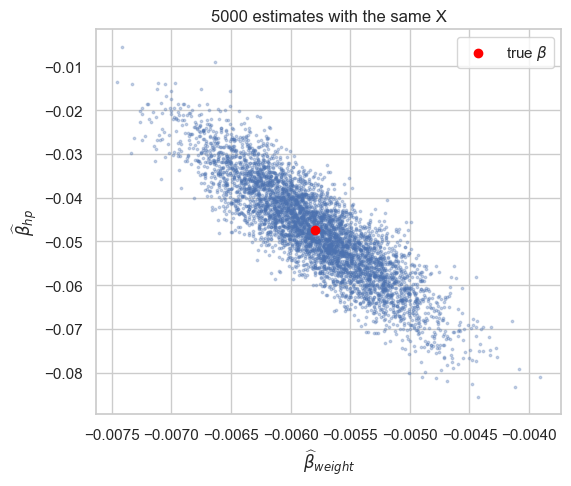

In [17]:
beta_true = model.params.to_numpy()
sigma_true = np.sqrt(s_n2)
n_sim = 5000

Y_sim = X @ beta_true + sigma_true * rng.standard_normal((n_sim, n))     # each row one data set
B_sim = np.linalg.lstsq(X, Y_sim.T, rcond=None)[0].T                      # all fits at once, n_sim x p
S2_sim = np.sum((Y_sim - B_sim @ X.T) ** 2, axis=1) / (n - p)

display(pd.DataFrame({'true beta': beta_true, 'mean of estimates': B_sim.mean(axis=0),
                      'sd theory sigma*sqrt(v_j)': sigma_true * np.sqrt(np.diag(XtX_inv)),
                      'sd simulated': B_sim.std(axis=0, ddof=1)}, index=X_df.columns))
print(f'sigma^2 = {sigma_true ** 2:.4f},  mean of s_n^2 = {S2_sim.mean():.4f}')
print(f'corr(b_weight, b_hp): theory {cov_b[1, 2] / (d[1] * d[2]):.3f}, simulated {np.corrcoef(B_sim[:, 1], B_sim[:, 2])[0, 1]:.3f}')

plt.figure(figsize=(6, 5))
plt.scatter(B_sim[:, 1], B_sim[:, 2], s=3, alpha=0.3)
plt.scatter(beta_true[1], beta_true[2], color='red', zorder=3, label='true $\\beta$')
plt.xlabel('$\\widehat{\\beta}_{weight}$'); plt.ylabel('$\\widehat{\\beta}_{hp}$'); plt.legend()
plt.title('5000 estimates with the same X')
plt.show()

Theorem 3.4 in numbers: the means of the estimates equal the true values, the simulated standard deviations agree with $\sigma\sqrt{v_j}$ up to the simulation error (the Monte Carlo error of a standard deviation is about $1/\sqrt{2 \cdot 5000} \approx 1$ %; the intercept is off by about 2 %, a slightly unlucky draw), the mean of $s_n^2$ equals $\sigma^2$, and the cloud of $(\widehat{\beta}_{\text{weight}}, \widehat{\beta}_{\text{hp}})$ is an inclined ellipse with correlation $-0.87$.

### 4.3 Small $n$: the $\chi^2$ and $t$ distributions and independence
With $n = 392$ the $t$ distribution is indistinguishable from $N(0,1)$. To see Theorem 3.5 at work we take a small design: ten cars (the heaviest car and nine random ones), weight in thousands of lb and horsepower in hundreds, so $n - m - 1 = 7$.

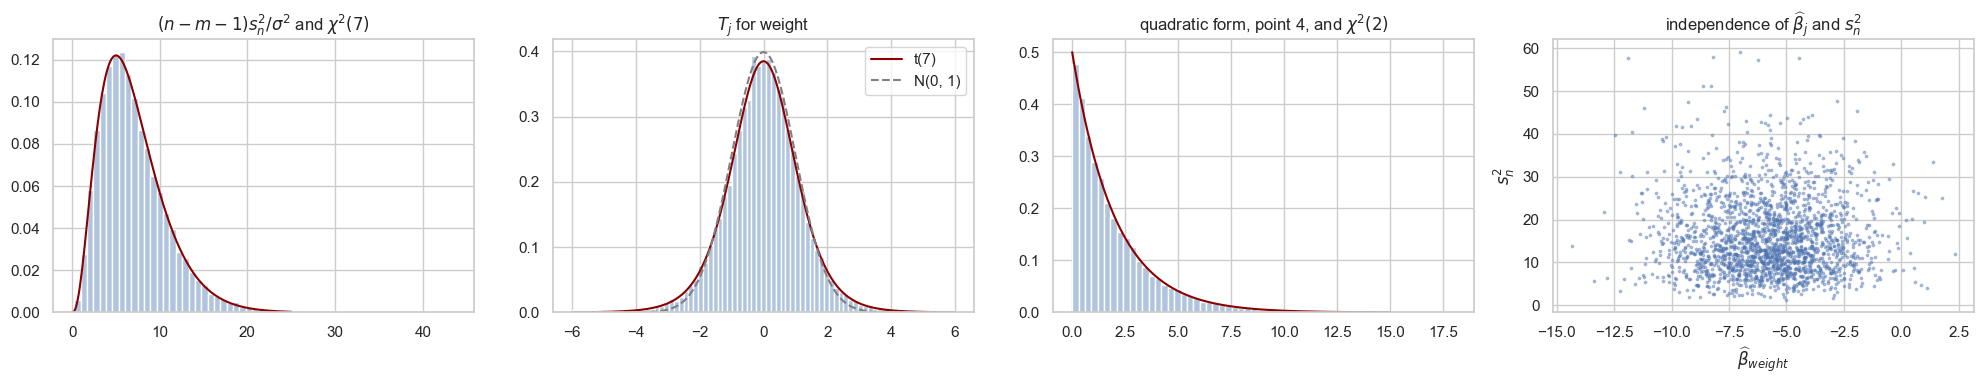

share of |T_j| > t_0.975(7) = 2.365: 0.0496
share of |T_j| > z_0.975 = 1.960        : 0.0894  (the normal quantile is wrong for small n)


In [18]:
small = pd.concat([cars.drop(index=cars['weight'].idxmax()).sample(9, random_state=3),
                   cars.loc[[cars['weight'].idxmax()]]])
Xs = np.column_stack([np.ones(len(small)), small['weight'] / 1000, small['horsepower'] / 100])
ns, ps = Xs.shape
beta_s = np.array([45.6, -5.8, -4.7])          # roughly the estimates of the full data, in the new units
sigma_s = 4.0
Xs_inv = np.linalg.inv(Xs.T @ Xs)
df_s = ns - ps

n_sim_s = 20000
Ys = Xs @ beta_s + sigma_s * rng.standard_normal((n_sim_s, ns))
Bs = np.linalg.lstsq(Xs, Ys.T, rcond=None)[0].T
S2s = np.sum((Ys - Bs @ Xs.T) ** 2, axis=1) / df_s

j = 1                                               # the weight coefficient
T_j = (Bs[:, j] - beta_s[j]) / np.sqrt(S2s * Xs_inv[j, j])
C_mat = np.array([[0, 1, 0], [0, 0, 1]])            # both slopes, r = 2 (not C: that name is patsy's C() in formulas)
Cdev = (Bs - beta_s) @ C_mat.T
Q_form = np.einsum('ij,jk,ik->i', Cdev, np.linalg.inv(C_mat @ Xs_inv @ C_mat.T), Cdev) / sigma_s ** 2

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
g = np.linspace(0, 25, 200)
axes[0].hist(df_s * S2s / sigma_s ** 2, bins=60, density=True, color='lightsteelblue')
axes[0].plot(g, stats.chi2.pdf(g, df_s), color='darkred')
axes[0].set_title(f'$(n-m-1)s_n^2/\\sigma^2$ and $\\chi^2({df_s})$')
g = np.linspace(-6, 6, 300)
axes[1].hist(np.clip(T_j, -6, 6), bins=np.linspace(-6, 6, 80), density=True, color='lightsteelblue')   # |T_j| > 6 (rare) in the end bins
axes[1].plot(g, stats.t.pdf(g, df_s), color='darkred', label=f't({df_s})')
axes[1].plot(g, stats.norm.pdf(g), color='gray', ls='--', label='N(0, 1)')
axes[1].set_title('$T_j$ for weight'); axes[1].legend()
g = np.linspace(0, 15, 200)
axes[2].hist(Q_form, bins=60, density=True, color='lightsteelblue')
axes[2].plot(g, stats.chi2.pdf(g, 2), color='darkred')
axes[2].set_title('quadratic form, point 4, and $\\chi^2(2)$')
axes[3].scatter(Bs[:2000, j], S2s[:2000], s=3, alpha=0.4)
axes[3].set_xlabel('$\\widehat{\\beta}_{weight}$'); axes[3].set_ylabel('$s_n^2$')
axes[3].set_title('independence of $\\widehat{\\beta}_j$ and $s_n^2$')
plt.tight_layout()
plt.show()

print(f'share of |T_j| > t_0.975({df_s}) = {stats.t.ppf(0.975, df_s):.3f}: {np.mean(np.abs(T_j) > stats.t.ppf(0.975, df_s)):.4f}')
print(f'share of |T_j| > z_0.975 = 1.960        : {np.mean(np.abs(T_j) > 1.96):.4f}  (the normal quantile is wrong for small n)')

All four points of Theorem 3.5 are visible: the histograms follow $\chi^2(7)$, $t(7)$ and $\chi^2(2)$, and the cloud of $(\widehat{\beta}_j, s_n^2)$ shows no relation. The $t(7)$ density has heavier tails than $N(0,1)$; using $1.96$ instead of $t_{0.975}(7) = 2.36$ would reject a true hypothesis in about 9 % of the cases instead of 5 %.

**Idea of the proof** (the linear algebra on p. 77). $\mathbf{M} = \mathbf{I}_n - \mathbf{H}$ is symmetric and idempotent, so $\mathbf{M} = \mathbf{Q}\boldsymbol{\Lambda}\mathbf{Q}^T$ with an orthogonal $\mathbf{Q}$ and eigenvalues only 0 and 1, exactly $h(\mathbf{M}) = \mathrm{tr}(\mathbf{M}) = n - m - 1$ of them equal to 1. With $\mathbf{Z} = \mathbf{Q}^T\mathbf{e}/\sigma \sim N_n(\mathbf{0}, \mathbf{I}_n)$ we get $\mathrm{SSE}/\sigma^2 = \mathbf{e}^T\mathbf{M}\mathbf{e}/\sigma^2 = \sum_{\lambda_i = 1} Z_i^2 \sim \chi^2(n-m-1)$ (point 2). And $\widehat{\boldsymbol{\beta}} - \boldsymbol{\beta} = (\mathbf{X}^T\mathbf{X})^{-1}\mathbf{X}^T\mathbf{e}$ and $\widehat{\mathbf{e}} = \mathbf{M}\mathbf{e}$ are jointly normal with $\mathsf{Cov}(\widehat{\boldsymbol{\beta}}, \widehat{\mathbf{e}}) = \sigma^2(\mathbf{X}^T\mathbf{X})^{-1}\mathbf{X}^T\mathbf{M} = \mathbf{0}$ (because $\mathbf{X}^T\mathbf{M} = \mathbf{0}$, i.e. $\mathbf{H}\mathbf{M} = \mathbf{0}$); uncorrelated jointly normal vectors are independent, and $s_n^2$ is a function of $\widehat{\mathbf{e}}$ (point 1). Point 3 is then the definition of the $t$ distribution: $N(0,1)$ divided by an independent $\sqrt{\chi^2(k)/k}$.

**From point 3 to a test and a confidence interval.** Point 3 says $T_j = \dfrac{\widehat{\beta}_j - \beta_j}{s_n\sqrt{v_j}} \sim t(n-m-1)$, with $v_j = \big[(\mathbf{X}^T\mathbf{X})^{-1}\big]_{jj}$. Exactly as for simple regression in Exercise 02 (Sections 7 and 8; its individual work was solved in Exercise 03):
- **$t$-test** of $H_0: \beta_j = b$ against $H_1: \beta_j \ne b$: reject when $\dfrac{|\widehat{\beta}_j - b|}{s_n\sqrt{v_j}} > t_{1-\alpha/2}(n-m-1)$. For $b = 0$ this is the column `t` of `summary()` and its $p$-value.
- **Confidence interval** (interval spolehlivosti) for $\beta_j$ with coverage $1 - \alpha$: $\ \widehat{\beta}_j \pm t_{1-\alpha/2}(n-m-1)\, s_n\sqrt{v_j}$ (statsmodels `conf_int()`, R `confint()`).

The two are the same statement: $H_0: \beta_j = b$ is rejected at level $\alpha$ exactly when $b$ lies outside the interval. Coverage $1 - \alpha$ means that over repeated samples the random interval contains the fixed true $\beta_j$ in a share $1 - \alpha$ of the cases. We check it on the simulated samples of the ten-car design.

,t_0.975(7) = 2.365,z_0.975 = 1.960 (wrong for small n)
Intercept,0.9498,0.9115
weight,0.9504,0.9106
horsepower,0.9509,0.9089


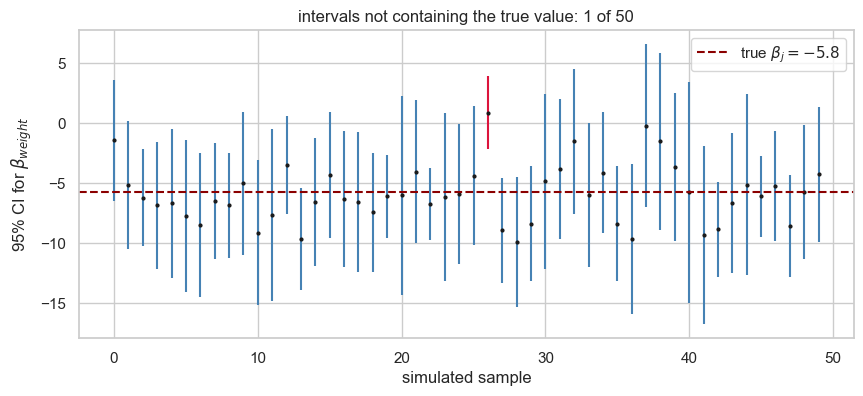

In [19]:
alpha = 0.05
se_s = np.sqrt(S2s[:, None] * np.diag(Xs_inv))       # s_n sqrt(v_j) for every sample and coefficient
coverage = {}
for name, q in [(f't_0.975({df_s}) = {stats.t.ppf(1 - alpha / 2, df_s):.3f}', stats.t.ppf(1 - alpha / 2, df_s)),
                ('z_0.975 = 1.960 (wrong for small n)', stats.norm.ppf(1 - alpha / 2))]:
    lower, upper = Bs - q * se_s, Bs + q * se_s
    coverage[name] = ((lower <= beta_s) & (beta_s <= upper)).mean(axis=0)
display(pd.DataFrame(coverage, index=['Intercept', 'weight', 'horsepower']).round(4))

# the first 50 intervals for the weight coefficient
q = stats.t.ppf(1 - alpha / 2, df_s)
k = np.arange(50)
lo, up = Bs[k, j] - q * se_s[k, j], Bs[k, j] + q * se_s[k, j]
miss = (lo > beta_s[j]) | (up < beta_s[j])
plt.figure(figsize=(10, 4))
plt.vlines(k, lo, up, color=np.where(miss, 'crimson', 'steelblue'))
plt.plot(k, Bs[k, j], 'k.', ms=4)
plt.axhline(beta_s[j], color='darkred', ls='--', label=f'true $\\beta_j = {beta_s[j]}$')
plt.xlabel('simulated sample'); plt.ylabel('95% CI for $\\beta_{weight}$'); plt.legend()
plt.title(f'intervals not containing the true value: {miss.sum()} of 50')
plt.show()

With the $t(7)$ quantile all three coverages are 95 % up to the simulation error; with $1.96$ they drop to about 91 %. The intervals have different lengths, because $s_n$ is random, and they are centered at different points: the interval is random, the parameter is fixed.

**Exercise on the board.** Prove points 1–3 of Theorem 3.4.
1. Write $\widehat{\boldsymbol{\beta}} = \boldsymbol{\beta} + (\mathbf{X}^T\mathbf{X})^{-1}\mathbf{X}^T\mathbf{e}$ and compute $\mathsf E\,\widehat{\boldsymbol{\beta}}$ and $\mathsf{Cov}\,\widehat{\boldsymbol{\beta}}$.
2. Use $\widehat{\mathbf{e}} = \mathbf{M}\mathbf{e}$ (Exercise 04) and the theorem from probability on p. 83 of the slides, $\mathsf E(\mathbf{Z}^T\mathbf{A}\mathbf{Z}) = \mathrm{tr}(\mathbf{A}\boldsymbol{\Sigma}) + \boldsymbol{\mu}^T\mathbf{A}\boldsymbol{\mu}$ for $\mathsf E\,\mathbf{Z} = \boldsymbol{\mu}$, $\mathsf{Cov}\,\mathbf{Z} = \boldsymbol{\Sigma}$, to compute $\mathsf E\,\mathrm{SSE}$.
3. Where exactly did you use that the errors are uncorrelated with a common variance? Where would you need normality?

<!--
Solution.
1. beta_hat = (X^T X)^{-1} X^T (X beta + e) = beta + (X^T X)^{-1} X^T e.
   E beta_hat = beta + (X^T X)^{-1} X^T E e = beta.
   Cov beta_hat = (X^T X)^{-1} X^T Cov(e) X (X^T X)^{-1} = sigma^2 (X^T X)^{-1} X^T X (X^T X)^{-1} = sigma^2 (X^T X)^{-1}.
2. SSE = e_hat^T e_hat = e^T M^T M e = e^T M e (M symmetric, idempotent). With mu = 0, Sigma = sigma^2 I:
   E SSE = tr(M sigma^2 I) = sigma^2 tr(M) = sigma^2 (n - m - 1), hence E s_n^2 = sigma^2.
3. Point 1 (unbiasedness) needs only E e = 0 and a fixed X of full rank. Cov(e) = sigma^2 I_n (uncorrelated,
   homoscedastic) is used only in points 2 and 3.
   Normality is needed for the distribution: beta_hat is a linear function of e, so it is normal (point 4);
   s_n^2 ~ chi^2 and independence need normality (Theorem 3.5).
-->

## 5. Residuals in the multiple model
This section uses pp. 108–110 of the slides; the lecture will come to them in the chapter on residuals, here we take them in advance.

### 5.1 Theorem 3.6: the residual vector
With $\widehat{\mathbf{y}} = \mathbf{H}\mathbf{y}$ the residual vector is $\widehat{\mathbf{e}} = \mathbf{y} - \widehat{\mathbf{y}} = (\mathbf{I}_n - \mathbf{H})\mathbf{y} = (\mathbf{I}_n - \mathbf{H})\mathbf{e}$. **Theorem 3.6**: for uncorrelated errors with $e_i \sim (0, \sigma^2)$
1. $\mathsf E\,\widehat{\mathbf{e}} = \mathbf{0}$, $\ \mathsf{Cov}\,\widehat{\mathbf{e}} = \sigma^2(\mathbf{I}_n - \mathbf{H})$,
2. if $\mathbf{e} \sim N_n(\mathbf{0}, \sigma^2\mathbf{I}_n)$, then $\widehat{\mathbf{e}} \sim N_n\big(\mathbf{0}, \sigma^2(\mathbf{I}_n - \mathbf{H})\big)$,
3. if the model has an intercept (the column of ones in $\mathbf{X}$), then $\sum_i \widehat{e}_i = 0$,
4. $\sum_i \widehat{e}_i\,\widehat{y}_i = 0$.

With $h_{ij} = \mathbf{H}_{ij}$: $\ \mathsf{Var}\,\widehat{e}_i = \sigma^2(1 - h_{ii})$ and $\mathsf{Cov}(\widehat{e}_i, \widehat{e}_j) = -\sigma^2 h_{ij}$ (slides p. 108). For simple regression $h_{ii} = \frac{1}{n} + \frac{(x_i - \overline{x})^2}{S_{xx}}$ and this is Theorem 2.7 from Exercise 03. Even when the errors are independent with equal variances, the residuals are **correlated** and have **unequal variances**; a point with large leverage has a small residual variance, because the fit is pulled towards it.

We check point 1 by simulation on the ten-car design of Section 4.3.

max |empirical Cov - sigma^2 (I - H)| = 0.233  (sigma^2 = 16.0)


,weight (1000 lb),hp (100),h_ii,Var(e_i)/sigma^2 theory,Var(e_i)/sigma^2 simulated
0,2.615,1.00,0.149,0.851,0.839
1,2.774,0.97,0.115,0.885,0.895
2,4.054,1.42,0.184,0.816,0.812
3,2.220,0.81,0.193,0.807,0.817
4,3.445,1.65,0.592,0.408,0.408
5,3.574,0.78,0.586,0.414,0.415
6,3.840,1.30,0.149,0.851,0.853
7,1.845,0.62,0.279,0.721,0.724
8,2.050,0.62,0.248,0.752,0.762
9,5.140,1.75,0.505,0.495,0.488


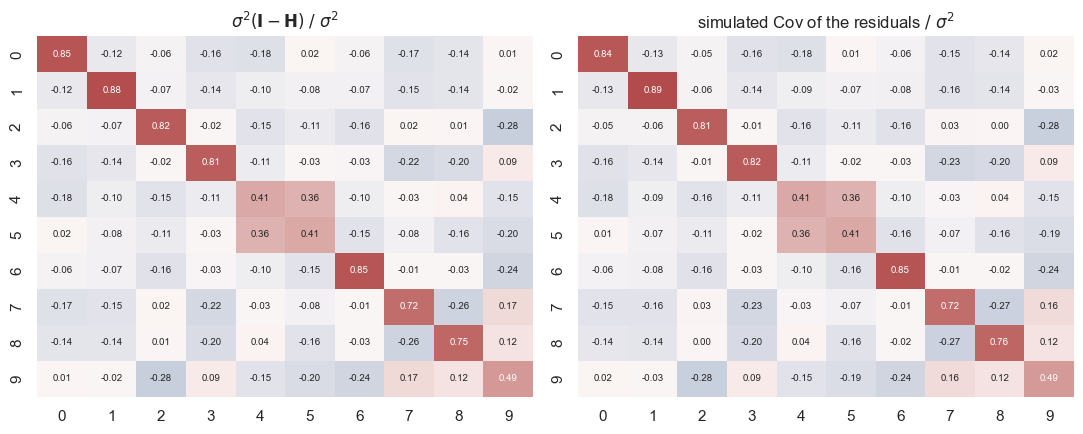

In [20]:
Hs = Xs @ Xs_inv @ Xs.T
E_res = Ys - Bs @ Xs.T                                  # residual vectors of the 20000 simulated data sets
cov_theory = sigma_s ** 2 * (np.eye(ns) - Hs)
cov_emp = np.cov(E_res, rowvar=False)
print(f'max |empirical Cov - sigma^2 (I - H)| = {np.abs(cov_emp - cov_theory).max():.3f}  (sigma^2 = {sigma_s ** 2})')

display(pd.DataFrame({'weight (1000 lb)': Xs[:, 1], 'hp (100)': Xs[:, 2], 'h_ii': np.diag(Hs),
                      'Var(e_i)/sigma^2 theory': 1 - np.diag(Hs),
                      'Var(e_i)/sigma^2 simulated': E_res.var(axis=0) / sigma_s ** 2}).round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, M_, title in [(axes[0], cov_theory, '$\\sigma^2(\\mathbf{I} - \\mathbf{H})$'), (axes[1], cov_emp, 'simulated Cov of the residuals')]:
    sns.heatmap(M_ / sigma_s ** 2, ax=ax, cmap='vlag', center=0, vmin=-1, vmax=1, annot=True, fmt='.2f', cbar=False,
                annot_kws={'size': 7})
    ax.set_title(title + ' $/\\ \\sigma^2$')
plt.tight_layout()
plt.show()

Three cars have $h_{ii} \approx 0.5$–$0.6$ and a residual variance of only 40–50 % of $\sigma^2$: the heaviest car (last row), but also cars 4 and 5, which lie inside the range of each variable (car 4 has the second largest horsepower, but only an average weight). Car 4 is powerful for its weight, car 5 weak for its weight; leverage measures an unusual **combination** of the regressors, which a look at each variable separately does not reveal. The off-diagonal elements are the covariances $-h_{ij}$: the residuals of ten independent errors are correlated, because they are bound by the $m+1 = 3$ linear constraints $\mathbf{X}^T\widehat{\mathbf{e}} = \mathbf{0}$ and live in a subspace of dimension $n - m - 1 = 7$.

Points 3 and 4, and the consequence $\mathrm{SST} = \mathrm{SSR} + \mathrm{SSE}$ (Exercise 04), on the real data:

In [21]:
e_hat = model.resid.to_numpy()
y_hat = model.fittedvalues.to_numpy()
SST, SSR, SSE = np.sum((y - y.mean()) ** 2), np.sum((y_hat - y.mean()) ** 2), np.sum(e_hat ** 2)
print(f'sum of residuals          = {e_hat.sum():.2e}')
print(f'sum of residuals * y_hat  = {e_hat @ y_hat:.2e}')
print(f'SST - SSR - SSE           = {SST - SSR - SSE:.2e}')

sum of residuals          = -1.46e-11
sum of residuals * y_hat  = -3.37e-10
SST - SSR - SSE           = 1.27e-11


### 5.2 Plot the residuals against $\widehat{y}$, not against $y$
Point 4 says the residuals are orthogonal to the fitted values, so a plot of $\widehat{e}_i$ against $\widehat{y}_i$ shows no linear trend when the model is right. Against the **observed** $y_i$ it always shows one: $\sum_i \widehat{e}_i (y_i - \overline{y}) = \sum_i \widehat{e}_i\,\widehat{e}_i = \mathrm{SSE}$, hence

$$\mathrm{corr}(\widehat{\mathbf{e}}, \mathbf{y}) = \frac{\mathrm{SSE}}{\sqrt{\mathrm{SSE}\cdot\mathrm{SST}}} = \sqrt{1 - R^2} > 0,$$

a positive trend that has nothing to do with the quality of the model. (This needs the intercept: point 3, $\sum_i \widehat{e}_i = 0$, is used twice, to subtract $\overline{y}$ and to center $\widehat{\mathbf{e}}$ in the correlation, and $R^2 = 1 - \mathrm{SSE}/\mathrm{SST}$ rests on $\mathrm{SST} = \mathrm{SSR} + \mathrm{SSE}$.)

corr(e_hat, y)     = 0.5419,  sqrt(1 - R^2) = 0.5419
corr(e_hat, y_hat) = 3.1e-16


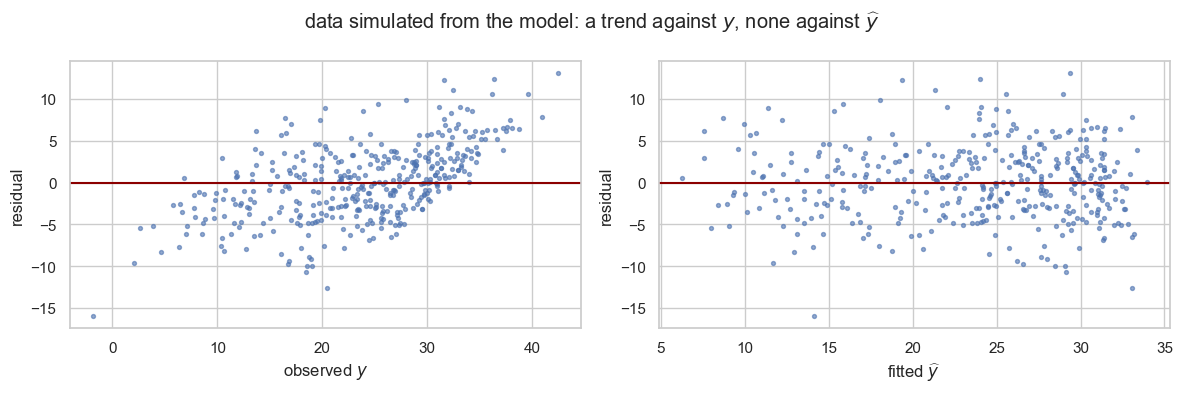

In [22]:
print(f'corr(e_hat, y)     = {np.corrcoef(e_hat, y)[0, 1]:.4f},  sqrt(1 - R^2) = {np.sqrt(1 - model.rsquared):.4f}')
print(f'corr(e_hat, y_hat) = {np.corrcoef(e_hat, y_hat)[0, 1]:.1e}')

# the same on data simulated from the model itself, where the model is certainly right
y_ok = Y_sim[0]
e_ok = y_ok - X @ np.linalg.lstsq(X, y_ok, rcond=None)[0]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_ok, e_ok, s=8, alpha=0.6); axes[0].set_xlabel('observed $y$')
axes[1].scatter(y_ok - e_ok, e_ok, s=8, alpha=0.6); axes[1].set_xlabel('fitted $\\widehat{y}$')
for ax in axes:
    ax.axhline(0, color='darkred'); ax.set_ylabel('residual')
fig.suptitle('data simulated from the model: a trend against $y$, none against $\\widehat{y}$')
plt.tight_layout()
plt.show()

### 5.3 Studentized residuals
Lecture 4 introduced the studentized residuals for simple regression (Remark 2.21, p. 60; Exercise 03). In the multiple model $h_{ii}$ replaces $\frac{1}{n} + \frac{(x_i - \overline{x})^2}{S_{xx}}$ (slides pp. 108–109):

$$\widehat{r}_i = \frac{\widehat{e}_i}{s_n\sqrt{1 - h_{ii}}} \quad \text{(internally studentized residuals, interně studentizovaná; also standardized residuals; R: `rstandard`)},$$

$$\widehat{t}_i = \frac{\widehat{e}_i}{\widehat{\sigma}_{(-i)}\sqrt{1 - h_{ii}}} \quad \text{(externally studentized residuals, externě studentizovaná; R: `rstudent`)},$$

where $\widehat{\sigma}^2_{(-i)} = \mathrm{SSE}_{(-i)}/(n-m-2)$ is the estimate of $\sigma^2$ from the model fitted without the $i$-th observation ($n - 1$ observations, $m + 1$ parameters), so that an outlier cannot inflate its own denominator. For small $h_{ii}$ and large $n$ all three, $\widehat{e}_i/s_n$, $\widehat{r}_i$ and $\widehat{t}_i$, behave alike and $\widehat{r}_i, \widehat{t}_i \approx N(0,1)$ (Remark 4.1). The externally studentized residuals and the other diagnostics based on leaving out one observation come in Exercise 07.

In [23]:
h = np.sum(np.linalg.qr(X)[0] ** 2, axis=1)            # leverages h_ii, as in Section 2
s_n = np.sqrt(s_n2)
r_manual = e_hat / (s_n * np.sqrt(1 - h))
infl = model.get_influence()
r_sm = infl.resid_studentized_internal                  # R: rstandard(mod)
t_sm = infl.resid_studentized_external                  # R: rstudent(mod)
print(f'max |manual - statsmodels| = {np.abs(r_manual - r_sm).max():.1e}')
print(f'h_ii: min {h.min():.4f}, mean (m+1)/n = {h.mean():.4f}, max {h.max():.4f}')

top = np.argsort(-np.abs(r_sm))[:5]
display(cars.loc[top, ['name', 'mpg', 'weight', 'horsepower', 'model_year']].assign(
    e_hat=e_hat[top], e_hat_over_s_n=e_hat[top] / s_n, h_ii=h[top], r_i=r_sm[top], t_i=t_sm[top]))

max |manual - statsmodels| = 4.4e-16
h_ii: min 0.0026, mean (m+1)/n = 0.0077, max 0.0950


,name,mpg,weight,horsepower,model_year,e_hat,e_hat_over_s_n,h_ii,r_i,t_i
320,mazda glc,46.6,2110,65.0,80,16.2601,3.8348,0.0054,3.8452,3.9154
381,oldsmobile cutlass ciera (diesel),38.0,3015,85.0,82,13.8499,3.2664,0.0056,3.2755,3.3173
324,vw dasher (diesel),43.4,2335,48.0,80,13.5597,3.1979,0.0107,3.2152,3.2546
388,vw pickup,44.0,2130,52.0,82,13.1611,3.1039,0.0076,3.1158,3.1514
323,vw rabbit c (diesel),44.3,2085,48.0,80,13.0111,3.0685,0.0085,3.0817,3.1160


With $n = 392$ the leverages are small (mean $(m+1)/n \approx 0.008$, maximum about $0.1$), so the three scales are almost the same; $\widehat{t}_i$ is a little larger than $\widehat{r}_i$ for the largest residuals, because removing such a car lowers the estimate of $\sigma$. The cars with the largest residuals are economical cars from 1980–1982, several of them diesels: high mpg for their weight and power.

### 5.4 Residual plots of a multiple model
The plots of Exercise 03 carry over, with one change: instead of one regressor $x$ we plot the residuals against **each** regressor (and, if available, against variables not in the model). The function below draws the histogram and the Q-Q plot of $\widehat{r}_i$, and $\widehat{r}_i$ against the fitted values, the observation order, and a list of variables.

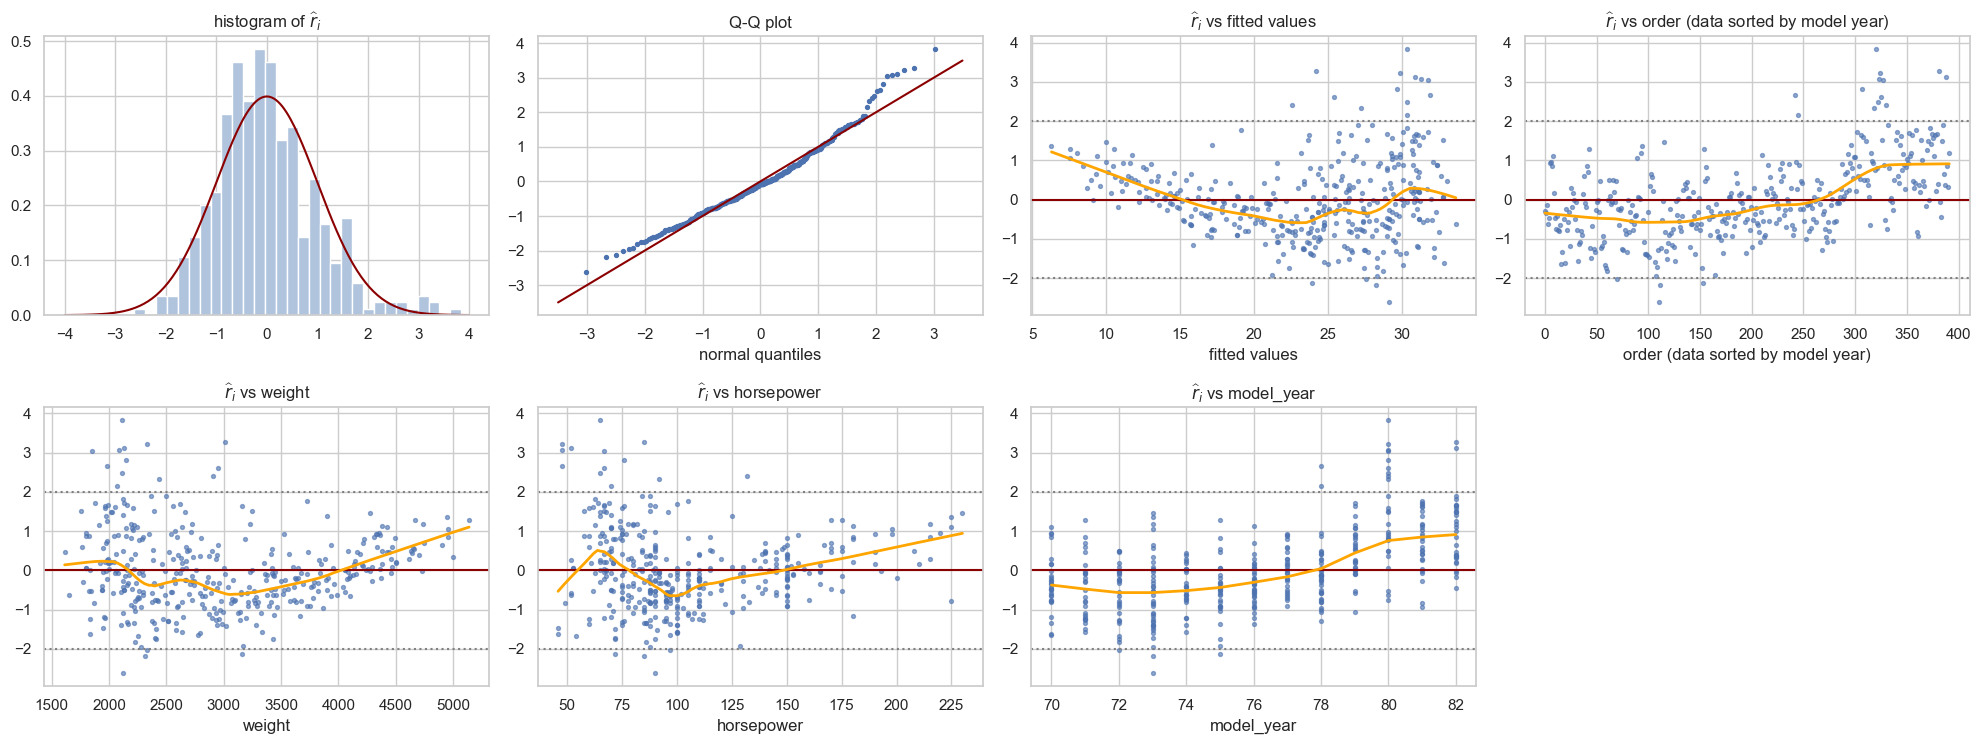

In [24]:
def residual_plots(fit, data, variables, order_name='observation order'):
    r = fit.get_influence().resid_studentized_internal
    k = len(r)
    panels = [('fitted values', np.asarray(fit.fittedvalues)), (order_name, np.arange(k))] + \
             [(v, data[v].to_numpy(dtype=float)) for v in variables]
    ncol = 4
    nrow = int(np.ceil((2 + len(panels)) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(20, 3.8 * nrow))
    axes = axes.ravel()
    axes[0].hist(r, bins=30, density=True, color='lightsteelblue')
    g = np.linspace(-4, 4, 200)
    axes[0].plot(g, stats.norm.pdf(g), color='darkred')
    axes[0].set_title('histogram of $\\widehat{r}_i$')
    q = stats.norm.ppf((np.arange(1, k + 1) - 0.5) / k)
    axes[1].scatter(q, np.sort(r), s=8)
    axes[1].plot([-3.5, 3.5], [-3.5, 3.5], color='darkred')
    axes[1].set_title('Q-Q plot'); axes[1].set_xlabel('normal quantiles')
    for ax, (lab, vals) in zip(axes[2:], panels):
        ax.scatter(vals, r, s=8, alpha=0.6)
        ax.axhline(0, color='darkred')
        for b in (-2, 2):
            ax.axhline(b, color='gray', ls=':')
        smooth = sm.nonparametric.lowess(r, vals, frac=0.3)
        ax.plot(smooth[:, 0], smooth[:, 1], color='orange', lw=2)
        ax.set_xlabel(lab); ax.set_title(f'$\\widehat{{r}}_i$ vs {lab}')
    for ax in axes[2 + len(panels):]:
        ax.axis('off')
    plt.tight_layout()
    plt.show()


residual_plots(model, cars, ['weight', 'horsepower', 'model_year'], 'order (data sorted by model year)')

Reading the plots for `mpg ~ weight + horsepower`:
- against the fitted values, weight and horsepower: a curved pattern, the residuals are negative in the middle and clearly positive for the heaviest cars (low fitted mpg); the straight plane underestimates mpg of the heaviest cars and overestimates the middle,
- the spread grows with the fitted values: light, economical cars vary more,
- against the order and against `model_year`, which is **not in the model**: a clear upward trend, newer cars are more economical than their weight and power predict. A variable missing from the model shows up in the residuals.
- the histogram and the Q-Q plot bend up in the right tail: a few cars are much more economical than predicted (the diesels of Section 5.3), the residuals are skewed to the right.

Adding `model_year` takes care of the trend:

R^2: 0.706 -> 0.808,   s_n: 4.24 -> 3.43


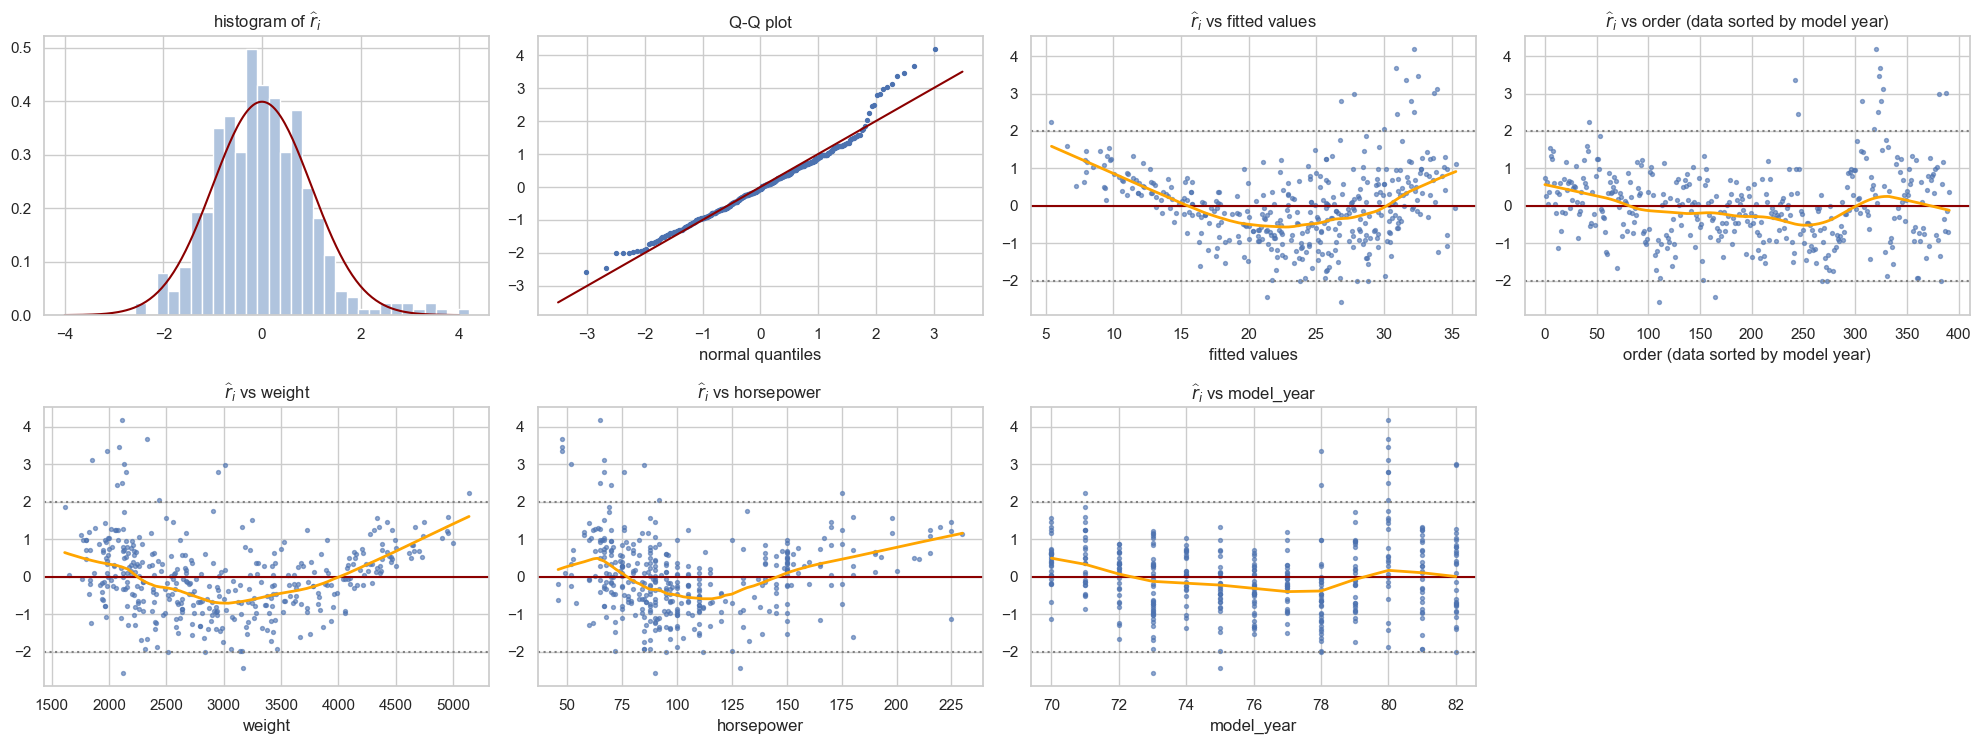

In [25]:
model_y = smf.ols('mpg ~ weight + horsepower + model_year', data=cars).fit()   # R: lm(mpg ~ weight + horsepower + model_year)
print(f'R^2: {model.rsquared:.3f} -> {model_y.rsquared:.3f},   s_n: {np.sqrt(model.scale):.2f} -> {np.sqrt(model_y.scale):.2f}')
residual_plots(model_y, cars, ['weight', 'horsepower', 'model_year'], 'order (data sorted by model year)')

The trend in the order and in `model_year` is largely gone, $R^2$ grows from about $0.71$ to $0.81$ and $s_n$ drops from $4.2$ to about $3.4$ mpg. The curvature in weight and horsepower is now even clearer, a **U-shape** with positive residuals at both ends (the trend in the year had partly hidden it), and the increasing spread and the right skewness remain; more variables will not remove them.

**A key to the shapes.** The slides (p. 112) say: residuals randomly scattered around zero without a trend, $\widehat{r}_i$ mostly within $\pm 2$, mean the model is fine; a **trend** indicates nonlinearity, a **funnel** a non-constant variance. What each shape means for the estimates and where the course deals with it:

| shape in the residual plot | assumption that fails | consequence | remedy (where) |
|---|---|---|---|
| curvature (U, arc) against $\widehat{y}$ or a regressor | linearity of $\mathsf E(Y \mid \mathbf{x})$ | the model is misspecified, $\widehat{\boldsymbol{\beta}}$ is biased for the true relationship | a term $x^2$, a transformation of $x$ or $y$; partial residual plots show which regressor (Exercise 07), transformations (Exercise 08) |
| funnel: spread grows or shrinks | constant variance | $\widehat{\boldsymbol{\beta}}$ stays unbiased (Theorem 3.4, point 1 does not need it), but $\sigma^2(\mathbf{X}^T\mathbf{X})^{-1}$ is wrong, so are the standard errors, $t$-tests and intervals; Gauss–Markov fails | variance-stabilizing transformation of $y$, weighted least squares (Exercise 08) |
| trend against a variable not in the model | a missing regressor | omitted-variable bias (newspaper and radio in Section 2) | add the variable, as `model_year` above |
| trend or waves against time or order | uncorrelated errors | standard errors too small | Durbin–Watson test (Exercise 08) |
| Q-Q plot off the line, isolated large $\widehat{r}_i$ | normality, outliers | for small $n$ the $t$ and $F$ distributions are not exact (Section 8.1); single points can pull the fit | transformation of $y$ (Exercise 08), influence measures (Exercise 07), robust regression (Exercise 09) |
| a sharp straight edge of points | a bounded response (e.g. many exact zeros) | no straight plane fits the kink | a different model; see the Credit data in Section 7 |

**A preview: a transformation of the response.** Exercise 08 will choose the transformation systematically (Box–Cox, slides pp. 133–141). Here we only try two natural candidates for `mpg ~ weight + horsepower`: the fuel consumption in L/100 km, $235.215/\text{mpg}$ (Box–Cox $\lambda = -1$, Exercise 03), and $\ln(\text{mpg})$ ($\lambda = 0$). The slides (p. 111) name the Breusch–Pagan test of constant variance; we only read its $p$-value, Exercise 08 explains it.

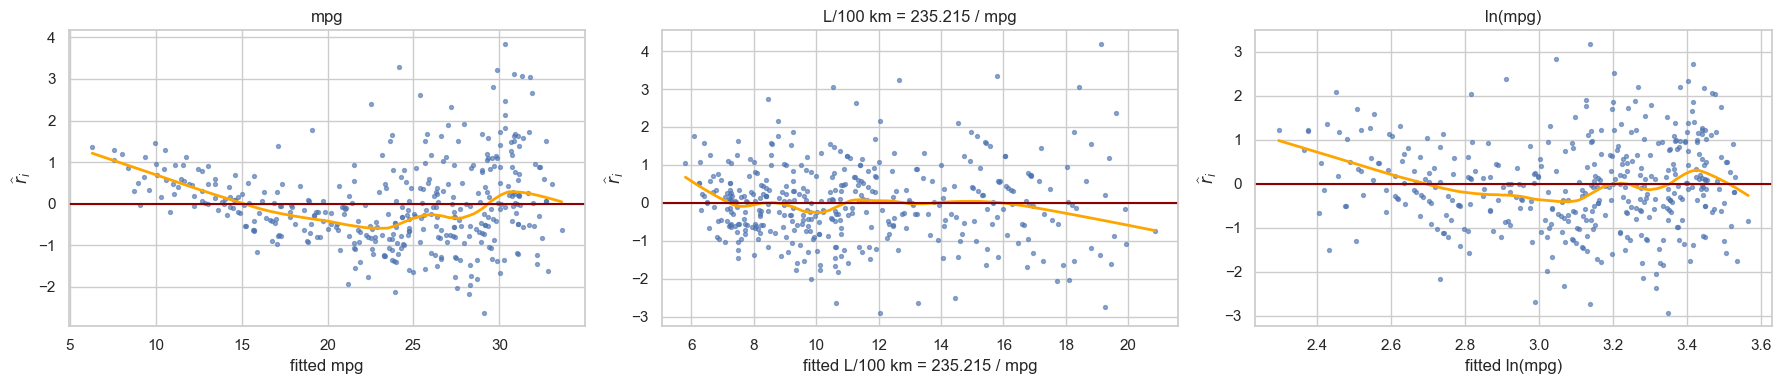

,R^2,Breusch-Pagan p-value
mpg,0.706,3.3e-06
L/100 km = 235.215 / mpg,0.815,2.6e-05
ln(mpg),0.788,1.5e-01


In [26]:
from statsmodels.stats.diagnostic import het_breuschpagan

responses = {'mpg': 'mpg', 'L/100 km = 235.215 / mpg': 'I(235.215 / mpg)', 'ln(mpg)': 'np.log(mpg)'}
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
rows = {}
for ax, (label, lhs) in zip(axes, responses.items()):
    fit_tr = smf.ols(f'{lhs} ~ weight + horsepower', data=cars).fit()
    r_tr = fit_tr.get_influence().resid_studentized_internal
    ax.scatter(fit_tr.fittedvalues, r_tr, s=8, alpha=0.6)
    smooth = sm.nonparametric.lowess(r_tr, fit_tr.fittedvalues, frac=0.3)
    ax.plot(smooth[:, 0], smooth[:, 1], color='orange', lw=2)
    ax.axhline(0, color='darkred')
    ax.set_xlabel(f'fitted {label}'); ax.set_ylabel('$\\widehat{r}_i$'); ax.set_title(label)
    rows[label] = {'R^2': fit_tr.rsquared, 'Breusch-Pagan p-value': het_breuschpagan(fit_tr.resid, fit_tr.model.exog)[1]}
plt.tight_layout()
plt.show()
display(pd.DataFrame(rows).T.style.format({'R^2': '{:.3f}', 'Breusch-Pagan p-value': '{:.1e}'}))

- **L/100 km** straightens the U: the consumption is nearly linear in weight and power (the physics: the energy needed grows with the mass). But the funnel stays, now heavy cars vary more.
- **$\ln(\text{mpg})$** stabilizes the variance (the Breusch–Pagan test no longer rejects), because the spread of mpg grows roughly in proportion to its mean, $\mathsf{Var}\,Y \approx \varphi\mu^2$, the case for which the slides (p. 135) recommend $\ln y$. Some curvature remains.
- One transformation need not repair everything, and the $R^2$ values of different responses are not comparable (each explains the variability of a different $y$). Exercise 08 will choose $\lambda$ by Box–Cox and combine transformations of $y$ and $x$.

## 6. Towards the overall $F$-test
Is the model useful at all, i.e. is at least one of $\beta_1, \dots, \beta_m$ nonzero? The slides (p. 82) warn against answering this with $m$ separate $t$-tests: each has the type I error $\alpha$, and the probability that **at least one** of them rejects a true $H_0$ grows with $m$. For independent tests it would be $1 - (1-\alpha)^m$.

A simulation: `mpg` against $m = 10$ regressors of pure noise, so that $H_0: \beta_1 = \dots = \beta_{10} = 0$ is true.

In [27]:
m_noise, n_rep = 10, 2000
crit = stats.t.ppf(0.975, n - m_noise - 1)
any_reject, n_reject = np.zeros(n_rep, bool), np.zeros(n_rep, int)
for k in range(n_rep):
    Xn = np.column_stack([np.ones(n), rng.standard_normal((n, m_noise))])
    b, *_ = np.linalg.lstsq(Xn, y, rcond=None)
    s2 = np.sum((y - Xn @ b) ** 2) / (n - m_noise - 1)
    T = b[1:] / np.sqrt(s2 * np.diag(np.linalg.inv(Xn.T @ Xn))[1:])
    n_reject[k] = np.sum(np.abs(T) > crit)
    any_reject[k] = n_reject[k] > 0
print(f'share of rejections per test     : {n_reject.mean() / m_noise:.3f}  (alpha = 0.05)')
print(f'P(at least one of 10 rejects)    : {any_reject.mean():.3f}  (1 - 0.95^10 = {1 - 0.95 ** 10:.3f})')

share of rejections per test     : 0.049  (alpha = 0.05)
P(at least one of 10 rejects)    : 0.394  (1 - 0.95^10 = 0.401)


Each test alone keeps 5 %, but in about 40 % of the data sets at least one noise variable looks "significant". Lowering $\alpha$ for every test (e.g. Bonferroni, $\alpha/m$) controls this, at the price of power. The slides add a second problem: with correlated regressors the individual $t$-tests can all be insignificant even when the model as a whole is strongly significant (large standard errors, Section 4.1 and the collinearity chapter).

The overall test uses one statistic. In the ANOVA spirit of simple regression, compare the explained sum of squares per regressor with $s_n^2$. **Theorem 3.8**: in the model with an intercept, $\mathbf{X}$ of full rank $m+1$ and uncorrelated errors $e_i \sim (0, \sigma^2)$ (normality is not needed), with the centered regressor matrix $\mathbf{X}_c$ (columns $x_{ij} - \overline{x}_j$) and $\boldsymbol{\beta}_s = (\beta_1, \dots, \beta_m)^T$,

$$\mathsf E\left(\frac{\mathrm{SSR}}{m}\right) = \sigma^2 + \frac{\boldsymbol{\beta}_s^T\mathbf{X}_c^T\mathbf{X}_c\boldsymbol{\beta}_s}{m}.$$

Under $H_0$ ($\boldsymbol{\beta}_s = \mathbf{0}$) both $\mathrm{SSR}/m$ and $s_n^2$ estimate $\sigma^2$; otherwise $\mathrm{SSR}/m$ is larger on average (Remark 3.5). Large values of $F = \dfrac{\mathrm{SSR}/m}{s_n^2}$ therefore speak against $H_0$. A check on the fixed design of Section 4.2:

In [28]:
Xc = X[:, 1:] - X[:, 1:].mean(axis=0)
m_ = p - 1
rows = {}
for label, beta_s_true in [('H0 true: beta_s = 0', np.zeros(m_)), ('beta_s = estimates', beta_true[1:])]:
    b_full = np.r_[beta_true[0], beta_s_true]
    Yk = X @ b_full + sigma_true * rng.standard_normal((n_sim, n))
    Bk = np.linalg.lstsq(X, Yk.T, rcond=None)[0].T
    Yh = Bk @ X.T
    SSR_k = np.sum((Yh - Yk.mean(axis=1, keepdims=True)) ** 2, axis=1)
    s2_k = np.sum((Yk - Yh) ** 2, axis=1) / (n - p)
    rows[label] = {'E(SSR/m) theory': sigma_true ** 2 + beta_s_true @ Xc.T @ Xc @ beta_s_true / m_,
                   'mean of SSR/m': (SSR_k / m_).mean(), 'mean of s_n^2': s2_k.mean(),
                   'mean of F': (SSR_k / m_ / s2_k).mean()}
pd.DataFrame(rows).T

,E(SSR/m) theory,mean of SSR/m,mean of s_n^2,mean of F
H0 true: beta_s = 0,17.9790,17.8122,17.9813,0.9961
beta_s = estimates,8430.5531,8433.6202,17.9920,471.2091


Under $H_0$ the two estimates of $\sigma^2$ agree and $F$ is about 1; for the real coefficients $\mathrm{SSR}/m$ is hundreds of times larger. How large is "large"? Under $H_0$ and normal errors $F \sim F(m, n-m-1)$ (Theorem 3.9), a distribution with the mean $(n-m-1)/(n-m-3) \approx 1.005$ here. This theorem, the ANOVA table of the multiple model and the adjusted $R^2$ come in Exercise 06.

## 7. Individual work: credit card balance
The file `Credit.csv` (from the book *An Introduction to Statistical Learning*) contains 400 credit card holders: `Balance` (average credit card debt in USD), `Income` (thousands of USD), `Limit` (credit limit), `Rating` (credit rating), `Cards`, `Age`, `Education`, and the factors `Gender`, `Student`, `Married`, `Ethnicity`. Write a short conclusion after each step.

1. Load the data (`index_col=0`), look at the factors and their levels. Is there anything suspicious in the levels? How many people have `Balance` equal to zero?
2. Fit `Balance ~ Income + Student` and `Balance ~ Income * Student`. For both models write the regression line for students and for non-students, interpret every coefficient with its units, and draw the data with the lines. What does the interaction coefficient and its standard error say?
3. Fit `Balance ~ Income + Ethnicity`. Which level is the reference? Refit with `Caucasian` as the reference level. Which numbers change, which do not, and why?
4. Fit `Balance ~ Income + Limit + Rating + Student`. Compute the standard errors by hand as $s_n\sqrt{v_j}$ and compare with `bse`. Compute the correlation matrix of the estimates from $s_n^2(\mathbf{X}^T\mathbf{X})^{-1}$. Which two estimates are most strongly correlated, and why? Compare the standard error of the `Limit` coefficient with the model without `Rating`.
5. Compare the coefficient of `Income` in step 4 with the simple regression `Balance ~ Income`. Explain the change (Frisch–Waugh–Lovell, Section 2).
6. For the model of step 4 verify Theorem 3.6, points 3 and 4, compute the internally studentized residuals by hand from $h_{ii}$, and draw the residual plots (Section 5.4, include `Income`, `Limit`, `Rating` and `Age`). Which pattern do you see in the plot against the fitted values, and what in the data causes it?

In [29]:
url_credit = 'https://raw.githubusercontent.com/francji1/01RAD/main/data/Credit.csv'
credit = pd.read_csv(url_credit, index_col=0)
credit.head()

,Income,Limit,Rating,Cards,Age,Education,Gender,Student,Married,Ethnicity,Balance
1,14.891,3606,283,2,34,11,Male,No,Yes,Caucasian,333
2,106.025,6645,483,3,82,15,Female,Yes,Yes,Asian,903
3,104.593,7075,514,4,71,11,Male,No,No,Asian,580
4,148.924,9504,681,3,36,11,Female,No,No,Asian,964
5,55.882,4897,357,2,68,16,Male,No,Yes,Caucasian,331


In [30]:
# your solution


## 8. Further material: normal errors and the Gauss–Markov theorem
Two more topics of the slides that the rest of this exercise does not need; Exercise 06 comes back to them. Both reuse the simulations of Section 4.

### 8.1 What needs normal errors?
Theorem 3.4 needs only uncorrelated errors with a constant variance; Theorem 3.5 needs normality. We repeat the simulation of Section 4.3 with errors of the same variance $\sigma^2$ but a different distribution: heavy-tailed $t(3)$ (rescaled to variance $\sigma^2$) and skewed (centered exponential). A useful check of independence is the correlation of $s_n^2$ with $|\widehat{\beta}_j - \beta_j|$, not only with $\widehat{\beta}_j$: zero correlation does not imply independence.

In [31]:
# uses the small design of Section 4.3 (Xs, beta_s, sigma_s, Xs_inv, df_s, ...): run Section 4 first
j = 1                                               # the weight coefficient again (the individual work may have reused j)
error_laws = {'normal': lambda size: rng.standard_normal(size),
              't(3), rescaled': lambda size: rng.standard_t(3, size) / np.sqrt(3),
              'exponential, centered': lambda size: rng.exponential(1.0, size) - 1}
rows = {}
for name, draw in error_laws.items():
    Ye = Xs @ beta_s + sigma_s * draw((n_sim_s, ns))
    Be = np.linalg.lstsq(Xs, Ye.T, rcond=None)[0].T
    S2e = np.sum((Ye - Be @ Xs.T) ** 2, axis=1) / df_s
    Te = (Be[:, j] - beta_s[j]) / np.sqrt(S2e * Xs_inv[j, j])
    rows[name] = {'mean b_weight (true -5.8)': Be[:, j].mean(),
                  'sd b_weight / theory': Be[:, j].std(ddof=1) /(sigma_s * np.sqrt(Xs_inv[j, j])),
                  'mean s_n^2 / sigma^2': S2e.mean() / sigma_s ** 2,
                  'corr(b_weight, s_n^2)': np.corrcoef(Be[:, j], S2e)[0, 1],
                  'corr(|b_weight - beta|, s_n^2)': np.corrcoef(np.abs(Be[:, j] - beta_s[j]), S2e)[0, 1],
                  'P(|T_j| > t_0.975)': np.mean(np.abs(Te) > stats.t.ppf(0.975, df_s))}
pd.DataFrame(rows).T

,mean b_weight (true -5.8),sd b_weight / theory,mean s_n^2 / sigma^2,"corr(b_weight, s_n^2)","corr(|b_weight - beta|, s_n^2)",P(|T_j| > t_0.975)
normal,-5.8046,1.0036,0.9945,-0.0028,0.0019,0.0511
"t(3), rescaled",-5.8042,0.9822,0.9658,-0.0110,0.3192,0.0537
"exponential, centered",-5.7900,1.0001,0.9942,-0.0380,0.2249,0.0564


- The first three columns agree for all three error laws (the $t(3)$ row is noisier, its fourth moment is infinite): **Theorem 3.4 does not need normality** (unbiasedness, the covariance matrix, $\mathsf E\,s_n^2 = \sigma^2$).
- With non-normal errors $s_n^2$ is clearly correlated with $|\widehat{\beta}_j - \beta_j|$: data sets with large errors give both a large $s_n^2$ and a far-off estimate. The correlation of $\widehat{\beta}_j$ itself with $s_n^2$ stays close to zero (slightly negative for the skewed errors), so a plain correlation would not reveal it: $\widehat{\boldsymbol{\beta}}$ and $s_n^2$ are **not independent**, point 1 of Theorem 3.5 fails.
- The $t(7)$ distribution of $T_j$ is no longer guaranteed. Here the rejection rates of a true hypothesis stay close to 5 % (the $t$-test is fairly robust to symmetric heavy tails, a little less to skewness), but that is an empirical finding for this design, not a theorem. For large $n$ the central limit theorem justifies the tests (remark after Theorem 3.9, Exercise 06).

### 8.2 Gauss–Markov: OLS is the best linear unbiased estimator
A **linear estimator** (Definition 3.1) is $\widetilde{\boldsymbol{\beta}} = \mathbf{A}\mathbf{Y}$ with a fixed matrix $\mathbf{A}$ of size $(m+1) \times n$. It is unbiased for every $\boldsymbol{\beta}$ if and only if $\mathbf{A}\mathbf{X} = \mathbf{I}_{m+1}$.

**Theorem 3.7 (Gauss–Markov).** Consider the model $\mathbf{Y} = \mathbf{X}\boldsymbol{\beta} + \mathbf{e}$, where $\mathbf{X}$ has full rank and $e_1, \dots, e_n$ are uncorrelated with $e_i \sim (0, \sigma^2)$. Then the OLS estimator $\widehat{\boldsymbol{\beta}}$ is **BLUE** (best linear unbiased estimator; nejlepší lineární nestranný odhad) of $\boldsymbol{\beta}$.

"Best" means the minimal variance: among all linear unbiased estimators, OLS gives every coefficient $\widehat{\beta}_j$ the smallest variance. The proof shows a little more: $\mathsf{Cov}\,\widetilde{\boldsymbol{\beta}} - \mathsf{Cov}\,\widehat{\boldsymbol{\beta}}$ is positive semidefinite, so also every linear combination $\mathbf{c}^T\boldsymbol{\beta}$ (a prediction, a difference of two slopes) has the smallest variance with OLS. Normality is not assumed. For normal errors OLS is even the best among **all** unbiased estimators (MVUE), linear or not.

An example of a competitor: weighted least squares with **arbitrary** weights $w_i > 0$, $\widetilde{\boldsymbol{\beta}} = (\mathbf{X}^T\mathbf{W}\mathbf{X})^{-1}\mathbf{X}^T\mathbf{W}\mathbf{Y}$, $\mathbf{W} = \mathrm{diag}(w_i)$. Here $\mathbf{A}\mathbf{X} = \mathbf{I}$, so it is linear and unbiased. (In Exercise 02 the Wald grouping estimator of the slope was another one.)

Lecture 2 proved the theorem for simple regression (p. 18, Definition 2.2; Exercise 02, Section 6): there a linear unbiased estimator $\sum_i c_iY_i$ of $\beta_1$ must satisfy $\sum_i c_i = 0$ and $\sum_i c_ix_i = 1$, and minimizing $\sum_i c_i^2$ under these constraints gives the OLS slope. The matrix proof below is the same idea for all coefficients at once.

In [32]:
# uses the simulation of Section 4.2 (sigma_true, beta_true, Y_sim, B_sim): run Section 4 first
# the design of Section 4.2 again (the individual work may have reused the names X, p)
y_df, X_df = dmatrices('mpg ~ weight + horsepower', data=cars, return_type='dataframe')
X = X_df.to_numpy()
p = X.shape[1]
XtX_inv = np.linalg.inv(X.T @ X)

w = 1 / cars['weight'].to_numpy() ** 2               # arbitrary weights, not justified by anything
W = np.diag(w)
A_wls = np.linalg.solve(X.T @ W @ X, X.T @ W)          # (X^T W X)^{-1} X^T W
print('A X = I:', np.allclose(A_wls @ X, np.eye(p)))

cov_ols = sigma_true ** 2 * XtX_inv
cov_wls = sigma_true ** 2 * A_wls @ A_wls.T
display(pd.DataFrame({'sd OLS': np.sqrt(np.diag(cov_ols)), 'sd other linear unbiased': np.sqrt(np.diag(cov_wls)),
                      'variance ratio': np.diag(cov_wls) / np.diag(cov_ols)}, index=X_df.columns))
# Var(c^T beta_tilde) / Var(c^T beta_hat) over all combinations c lies between the smallest and the largest
# generalized eigenvalue of (cov_wls, cov_ols); Gauss-Markov says all of them are >= 1
ratios = sla.eigh(cov_wls, cov_ols, eigvals_only=True)
print('variance ratio other / OLS, best and worst linear combination:', ratios.min().round(4), ratios.max().round(4))

B_wls = Y_sim @ A_wls.T                                # the same 5000 simulated data sets as in Section 4.2
print('\nsimulation, mean of the other estimator:', B_wls.mean(axis=0), ' true:', beta_true)
print('simulation, sd OLS  :', B_sim.std(axis=0, ddof=1))
print('simulation, sd other:', B_wls.std(axis=0, ddof=1))

A X = I: True


,sd OLS,sd other linear unbiased,variance ratio
Intercept,0.7932,0.8903,1.2599
weight,0.0005,0.0006,1.2535
horsepower,0.0111,0.0125,1.2771


variance ratio other / OLS, best and worst linear combination: 1.0001 1.3481

simulation, mean of the other estimator: [45.6445 -0.0058 -0.0474]  true: [45.6402 -0.0058 -0.0473]
simulation, sd OLS  : [0.7753 0.0005 0.0111]
simulation, sd other: [0.8765 0.0006 0.0126]


Both estimators are unbiased, but the arbitrary weights inflate the variance of every coefficient. Over all linear combinations $\mathbf{c}^T\boldsymbol{\beta}$ the ratio $\mathsf{Var}\,\mathbf{c}^T\widetilde{\boldsymbol{\beta}} / \mathsf{Var}\,\mathbf{c}^T\widehat{\boldsymbol{\beta}}$ is never below 1, as Gauss–Markov says; for the best combination the competitor is almost as good as OLS, for the worst one its variance is about a third larger. Two remarks for later:
- If the variances of the errors really differ, $\mathsf{Var}\,e_i = \sigma^2/w_i$, the assumptions of Gauss–Markov fail and the **weighted** least squares with the right weights wins (WLS, later in the course).
- "Best" is only among **linear unbiased** estimators. A biased estimator can have a smaller mean squared error; ridge regression at the end of the semester is exactly such an estimator.

**Exercise on the board.** Prove the Gauss–Markov theorem. Let $\widetilde{\boldsymbol{\beta}} = \mathbf{A}\mathbf{Y}$ with $\mathbf{A}\mathbf{X} = \mathbf{I}$, and write $\mathbf{A} = (\mathbf{X}^T\mathbf{X})^{-1}\mathbf{X}^T + \mathbf{D}$.
1. Show that $\mathbf{D}\mathbf{X} = \mathbf{0}$.
2. Compute $\mathsf{Cov}\,\widetilde{\boldsymbol{\beta}}$ and show that $\mathsf{Cov}\,\widetilde{\boldsymbol{\beta}} - \mathsf{Cov}\,\widehat{\boldsymbol{\beta}} = \sigma^2\mathbf{D}\mathbf{D}^T$.
3. Why is $\mathbf{D}\mathbf{D}^T$ positive semidefinite, and what does it mean for $\mathsf{Var}\,\mathbf{c}^T\widetilde{\boldsymbol{\beta}}$?

<!--
Solution.
1. A X = (X^T X)^{-1} X^T X + D X = I + D X = I, hence D X = 0 (and X^T D^T = 0).
2. Cov(A Y) = sigma^2 A A^T = sigma^2 [(X^T X)^{-1} X^T + D][X (X^T X)^{-1} + D^T]
   = sigma^2 [(X^T X)^{-1} + (X^T X)^{-1} X^T D^T + D X (X^T X)^{-1} + D D^T] = sigma^2 (X^T X)^{-1} + sigma^2 D D^T.
3. c^T D D^T c = ||D^T c||^2 >= 0 for every c, so D D^T is positive semidefinite and
   Var(c^T beta_tilde) = Var(c^T beta_hat) + sigma^2 ||D^T c||^2 >= Var(c^T beta_hat), with equality for all c iff D = 0,
   i.e. the OLS estimator. Normality was not used.
-->

## 9. What to remember
- A dummy variable shifts the line of one group (parallel lines); an interaction changes its slope. With an interaction, the dummy coefficient is the group difference **at $x = 0$**; center $x$ to make it meaningful. The interaction model gives the same two lines as separate regressions.
- A factor with $k$ levels gives $k - 1$ dummies; their coefficients are differences from the reference level. Changing the reference level is a reparametrization: other coefficients, the same fit.
- Theorem 3.4 (no normality needed): $\mathsf E\,\widehat{\boldsymbol{\beta}} = \boldsymbol{\beta}$, $\mathsf{Cov}\,\widehat{\boldsymbol{\beta}} = \sigma^2(\mathbf{X}^T\mathbf{X})^{-1}$, $\mathsf E\,s_n^2 = \sigma^2$. Standard errors $s_n\sqrt{v_j}$, estimated covariance matrix $s_n^2(\mathbf{X}^T\mathbf{X})^{-1}$ (`cov_params`, R `vcov`). Correlated regressors give correlated estimates.
- Theorem 3.5 (normal errors): $\widehat{\boldsymbol{\beta}}$ and $s_n^2$ independent, $(n-m-1)s_n^2/\sigma^2 \sim \chi^2(n-m-1)$, $T_j \sim t(n-m-1)$, the quadratic form $\sim \chi^2(r)$. Hence the $t$-test and the interval $\widehat{\beta}_j \pm t_{1-\alpha/2}(n-m-1)\,s_n\sqrt{v_j}$, with the $t$ quantile, not $1.96$. Simulate with a **fixed** $\mathbf{X}$ to check such statements.
- Gauss–Markov (Section 8): among linear unbiased estimators OLS has the smallest covariance matrix; biased or nonlinear estimators can still be better. Theorem 3.4, points 1–3, holds without normality, point 4 and Theorem 3.5 do not.
- $\mathsf{Cov}\,\widehat{\mathbf{e}} = \sigma^2(\mathbf{I}_n - \mathbf{H})$: residuals are correlated and have variances $\sigma^2(1 - h_{ii})$. Use $\widehat{r}_i = \widehat{e}_i/(s_n\sqrt{1-h_{ii}})$, plot against $\widehat{y}$ (never against $y$), against each regressor and against variables not in the model.
- Many $t$-tests inflate the overall type I error; the overall $F$-test compares $\mathrm{SSR}/m$ with $s_n^2$, both estimate $\sigma^2$ under $H_0$.